<a href="https://colab.research.google.com/github/Singleeee/T3-IA-Redes-Neurais/blob/main/Neural_Network.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Projeto 3 — Redes Neurais: classificação de subgêneros de ficção científica

**Dataset:** [Science Fiction Books (10,000+)](https://www.kaggle.com/datasets/tanguypledel/science-fiction-books-subgenres) — descrição textual + gêneros de ~10 mil livros.
**Tarefa:** a partir da descrição do livro, prever o subgênero (problema **multiclasse desbalanceado**).

| # | Etapa | Requisito atendido |
|---|-------|--------------------|
| 1 | Carregamento e pré-processamento | seleção de classes, limpeza, TF-IDF |
| 2 | MLP manual (NumPy) | 2 camadas ocultas, forward, backprop, Adam, L2 |
| 3 | MLP em Keras/TensorFlow | modelo equivalente para validar a rede manual |
| 4 | Hiperparâmetros + 5-fold CV | ReLU×Sigmoide, L2×sem L2, nº de neurônios, média e IC 95% |
| 5 | Diagnósticos, métricas, pesos | curvas de aprendizado, heatmaps, saturação, AUROC/P/R/F1, baseline |
| 6 | Embeddings Skip-Gram | substitui TF-IDF, 1 camada oculta |
| 7 | Resumo e conclusão | tabelas e gráficos consolidados |

**Como executar:** Kaggle/Colab (internet ligada: baixa o dataset via `kagglehub`) ou local (coloque o CSV em `./data/` ou defina `SF_CSV=/caminho/arquivo.csv`).
Todas as figuras e tabelas são salvas em `./outputs/`. Para um teste rápido do notebook inteiro use `NB_FAST=1`.

## O que mudou nesta versão (diagnóstico da execução anterior)

| Problema observado | Causa real | Correção |
|---|---|---|
| Só **206 livros** (130 treino / 33 val / 41 teste) | O dataset é **um CSV por subgênero** (`sf_cyberpunk.csv`, `sf_alternate_history.csv`, ...). A versão anterior abriu **apenas um** arquivo e ainda filtrava por rótulos ruins | Carrega **todos** os `sf_*.csv`; o **rótulo é o arquivo** de origem; livros repetidos em 2+ arquivos são tratados explicitamente |
| Rótulos como `'science fiction fantasy': 3` | A coluna `Genres` é um **dicionário em texto** `{gênero: votos}`; o `split(",")` o quebrava | `Genres` **não é mais usada como entrada** (vazaria o rótulo); só é lida, via `ast.literal_eval`, no modo de contingência de um único CSV |
| Overfitting severo (F1 treino = 1,00; variância ≈ 0,95) | 923 atributos e ~260 mil pesos para 130 exemplos | Mais dados, TF-IDF com `min_df=5`, redes menores, **early stopping** com *restore best weights*, L2 |
| Seleção pouco confiável de hiperparâmetros | Validação minúscula | 5-fold sobre milhares de livros; early stopping usa uma fatia **interna** do treino (a fold de validação continua limpa) |

Também incorporamos técnicas do livro *Mãos à Obra: Aprendizado de Máquina com Scikit-Learn* (as páginas citadas são as do livro): parada antecipada com paciência (p. 139 e 313), L2 só nos pesos (p. 313-315), curvas de aprendizado (p. 127-131), precisão/revocação × ROC (p. 90-97) e análise de erros pela matriz de confusão (p. 100-104).

## 1. Carregamento e pré-processamento
### 1.1 Imports e configuração

In [27]:
# Install dependencies as needed:
# !pip install kagglehub pandas
import kagglehub
import pandas as pd
from pathlib import Path

# Baixa o dataset do Kaggle (retorna o caminho da pasta onde foi salvo)
print("Baixando o dataset...")
dataset_dir = kagglehub.dataset_download("tanguypledel/science-fiction-books-subgenres")
print("Dataset salvo em:", dataset_dir)

# Encontra o arquivo CSV na pasta do dataset
csv_files = list(Path(dataset_dir).rglob("*.csv"))
if not csv_files:
    raise FileNotFoundError("Nenhum arquivo CSV encontrado no dataset baixado.")

file_path = csv_files[0]
print(f"Carregando o arquivo: {file_path.name}")

# Carrega o DataFrame usando o pandas diretamente
df = pd.read_csv(file_path)

print("Primeiros 5 registros:")
display(df.head())

Baixando o dataset...
Using Colab cache for faster access to the 'science-fiction-books-subgenres' dataset.
Dataset salvo em: /kaggle/input/science-fiction-books-subgenres
Carregando o arquivo: sf_cyberpunk.csv
Primeiros 5 registros:


,Book_Title,Original_Book_Title,Author_Name,Edition_Language,Rating_score,Rating_votes,Review_number,Book_Description,Year_published,Genres,url
0,Neuromancer,Neuromancer,William Gibson,English,3.90,268536,9800,Hotwired to the leading edges of art and techn...,1984,"{'Science Fiction': 6796, 'Fiction': 3550, 'Sc...",https://www.goodreads.com/book/show/6088007-ne...
1,Snow Crash,Snow Crash,Neal Stephenson,English,4.02,241095,9391,"In reality, Hiro Protagonist delivers pizza fo...",1992,"{'Science Fiction': 5069, 'Fiction': 3067, 'Sc...",https://www.goodreads.com/book/show/40651883-s...
2,Count Zero,Count Zero,William Gibson,English,4.01,46114,1219,A corporate mercenary wakes in a reconstructed...,1986,"{'Science Fiction': 1480, 'Science Fiction (Cy...",https://www.goodreads.com/book/show/22200.Coun...
3,Altered Carbon,Altered Carbon,Richard K. Morgan,English,4.05,90069,5990,Four hundred years from now mankind is strung ...,2002,"{'Science Fiction': 3185, 'Fiction': 1087, 'Sc...",https://www.goodreads.com/book/show/40792913-a...
4,Mona Lisa Overdrive,Mona Lisa Overdrive,William Gibson,English,3.99,37399,957,"William Gibson, author of the extraordinary mu...",1988,"{'Science Fiction': 1337, 'Science Fiction (Cy...",https://www.goodreads.com/book/show/154091.Mon...


In [28]:
!pip install gensim

In [29]:
import os, re, ast, time, itertools, warnings
from collections import Counter, defaultdict
from pathlib import Path

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import sparse, stats

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report)
from sklearn.dummy import DummyClassifier

import tensorflow as tf
from tensorflow import keras
from gensim.models import Word2Vec

SEED = 42
np.random.seed(SEED); tf.random.set_seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold"})

FAST = os.environ.get("NB_FAST", "0") == "1"      # modo de depuração (poucas épocas)
OUT = Path("outputs"); (OUT / "figs").mkdir(parents=True, exist_ok=True)

CFG = dict(
    # ---- dados
    N_CLASSES     = 8,                # nº máximo de subgêneros (os maiores) -> problema multiclasse desbalanceado
    SUBGENRES     = None,             # ex.: ["cyberpunk", "space opera"] (nomes dos arquivos sem "sf_")
    MIN_PER_CLASS = 150,              # ignora subgêneros com menos livros que isso
    MULTI_POLICY  = "drop",           # livro presente em 2+ arquivos: "drop" (descarta) | "rarest" (fica no subgênero menor)
    MIN_TOKENS    = 10,               # descarta descrições muito curtas
    # ---- representação
    MAX_FEATURES  = 4000,
    MIN_DF        = 2 if FAST else 5, # palavra precisa aparecer em >= MIN_DF descrições
    # ---- treino
    HIDDEN        = (64, 32),         # arquitetura de referência (2 camadas ocultas)
    GRID_HIDDEN   = [(32, 16), (64, 32), (128, 64)],
    EPOCHS        = 6 if FAST else 100,   # máximo de épocas (o early stopping decide quando parar)
    PATIENCE      = 2 if FAST else 8,
    ES_VAL_FRAC   = 0.10,             # fatia interna do treino usada só para early stopping
    EPOCHS_TRACK  = 4 if FAST else 30,    # épocas fixas (sem ES) para heatmaps/saturação
    BATCH         = 128,
    LR            = 1e-3,
    L2            = 5e-4,             # λ em  CE + λ·ΣW²  (só pesos, não bias)
    CLASS_WEIGHT  = False,            # True = pondera a perda pelo inverso da frequência da classe
    # ---- embeddings
    EMB_DIM       = 10 if FAST else 50,
    EMB_MAXLEN    = 10 if FAST else 40,
    W2V_EPOCHS    = 3 if FAST else 20,
)
TEST_RESULTS = []                      # acumula métricas de teste de todos os modelos (usado na etapa 7)
print("FAST =", FAST, "| TF:", tf.__version__)

FAST = False | TF: 2.21.0


### 1.2 Leitura dos CSVs e construção do problema multiclasse

O rótulo de cada livro é o **arquivo (subgênero) de onde ele veio**. Mostramos quantos livros há por arquivo, quantos aparecem em mais de um (ambíguos) e o que sobra depois dos filtros.

In [30]:
def candidate_csvs():
    # 1) SF_CSV (arquivo ou pasta)  2) sf_*.csv nas pastas usuais  3) kagglehub  4) qualquer CSV
    env = os.environ.get("SF_CSV")
    if env:
        p = Path(env)
        if p.is_dir():
            return sorted(p.rglob("*.csv"))
        if p.exists():
            return [p]
    found = []
    for root in [".", "data", "/kaggle/input", "/content", "/mnt/user-data/uploads"]:
        p = Path(root)
        if p.exists():
            found += [c for c in p.rglob("*.csv") if "outputs" not in c.parts]
    sf = [c for c in found if c.name.lower().startswith("sf_")]
    if sf:
        return sorted(set(sf))
    try:
        import kagglehub
        d = kagglehub.dataset_download("tanguypledel/science-fiction-books-subgenres")
        got = list(Path(d).rglob("*.csv"))
        if got:
            return sorted(got)
    except Exception as e:
        print("kagglehub indisponível:", e)
    return sorted(set(found))

def read_any(path):
    for enc in ("utf-8", "latin-1"):
        try:
            return pd.read_csv(path, encoding=enc)
        except UnicodeDecodeError:
            continue
    return pd.read_csv(path, encoding="utf-8", encoding_errors="ignore")

def subgenre_name(stem):
    return re.sub(r"^sf_", "", stem.lower()).replace("_", " ").strip()

frames = []
for c in candidate_csvs():
    t = read_any(c)
    dcol = next((x for x in t.columns if "desc" in x.lower()), None)
    if dcol is None:
        continue
    t = t.rename(columns={dcol: "description"})
    t["subgenre"] = subgenre_name(c.stem)
    t["source_file"] = c.name
    frames.append(t)
if not frames:
    raise FileNotFoundError("Nenhum CSV com coluna de descrição foi encontrado. Baixe o dataset do Kaggle, "
                            "coloque os sf_*.csv em ./data/ ou defina SF_CSV=/pasta/ou/arquivo.csv")

MODE = "files" if len(frames) >= 2 else "genres_dict"
print(f"{len(frames)} arquivo(s) carregado(s) -> modo '{MODE}'")
print("Colunas do 1º arquivo:", list(frames[0].columns))

12 arquivo(s) carregado(s) -> modo 'files'
Colunas do 1º arquivo: ['Book_Title', 'Original_Book_Title', 'Author_Name', 'Edition_Language', 'Rating_score', 'Rating_votes', 'Review_number', 'description', 'Year_published', 'Genres', 'url', 'subgenre', 'source_file']


Livros únicos: 11104 | em 2+ subgêneros (ambíguos): 2550 (23.0%)

Livros por arquivo (subgênero):
subgenre
aliens                1250
steampunk             1250
robots                1250
military              1250
alternate history     1249
apocalyptic           1248
time travel           1248
alternate universe    1247
hard                  1246
cyberpunk             1244
dystopia              1242
space opera           1235

Classes escolhidas: ['time travel', 'aliens', 'steampunk', 'cyberpunk', 'robots', 'military', 'alternate universe', 'alternate history']
Livros mantidos: 6396

8 classes | razão de desbalanceamento (maior/menor) = 1.6x


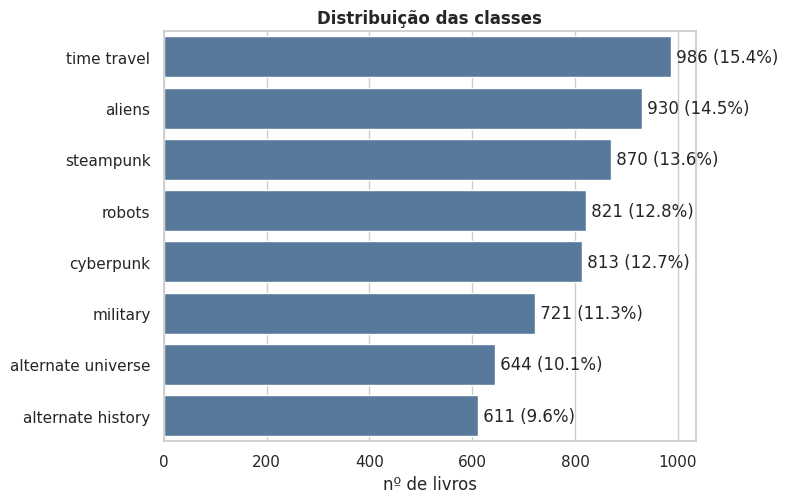

Exemplo limpo: starting sucks moved west virginia right senior year pretty resigned accents dodgy internet access lot boring spotted hot neighbor looming height eerie green eyes things looking opened mouth daemon in ...


In [31]:
if MODE == "files":
    raw = pd.concat(frames, ignore_index=True)
    key_col = "url" if "url" in raw.columns else next(c for c in raw.columns if "title" in c.lower())
    raw["key"] = raw[key_col].astype(str).str.strip().str.lower()

    per_file = raw.groupby("subgenre")["key"].nunique().sort_values(ascending=False)
    n_lab = raw.groupby("key")["subgenre"].nunique()
    n_multi = int((n_lab > 1).sum())
    print(f"Livros únicos: {raw['key'].nunique()} | em 2+ subgêneros (ambíguos): {n_multi} ({n_multi / raw['key'].nunique():.1%})")
    print("\nLivros por arquivo (subgênero):"); print(per_file.to_string())

    if CFG["MULTI_POLICY"] == "drop":
        raw = raw[~raw["key"].isin(n_lab[n_lab > 1].index)]
    else:                                                   # "rarest": fica no subgênero com menos livros
        raw = raw.assign(_size=raw["subgenre"].map(per_file)).sort_values("_size")
    raw = raw.drop_duplicates("key")
else:
    # contingência: um único CSV; extrai o subgênero mais votado de "Genres" (dicionário {gênero: votos})
    print("AVISO: só um CSV encontrado; use os 'sf_*.csv' completos para obter o conjunto de dados inteiro.")
    raw = frames[0].copy()
    SUBRE = re.compile(r"^science fiction \((.+?)\)\s*$", re.I)
    def top_sub(cell):
        try:
            d = ast.literal_eval(str(cell))
        except Exception:
            return None
        c = {SUBRE.match(k.strip()).group(1).lower(): v for k, v in d.items() if SUBRE.match(k.strip())}
        return max(c, key=c.get) if c else None
    raw["subgenre"] = raw["Genres"].map(top_sub)
    raw = raw.dropna(subset=["subgenre"])

counts = raw["subgenre"].value_counts()
if CFG["SUBGENRES"]:
    chosen = [s.lower() for s in CFG["SUBGENRES"]]
else:
    chosen = counts[counts >= CFG["MIN_PER_CLASS"]].head(CFG["N_CLASSES"]).index.tolist()
raw = raw[raw["subgenre"].isin(chosen)]
print("\nClasses escolhidas:", chosen)

df = pd.DataFrame({"raw": raw["description"].astype(str).values, "label_name": raw["subgenre"].values})

# --- limpeza do texto ---
RE_HTML, RE_URL, RE_NON = re.compile(r"<[^>]+>"), re.compile(r"https?://\S+|www\.\S+"), re.compile(r"[^a-z\s]")
STOP = set(ENGLISH_STOP_WORDS)

def clean_text(s):
    s = RE_URL.sub(" ", RE_HTML.sub(" ", str(s).lower())).replace("'", "")
    return " ".join(t for t in RE_NON.sub(" ", s).split() if len(t) > 2 and t not in STOP)

df["text"] = df["raw"].map(clean_text)
df = df[df["text"].str.split().str.len() >= CFG["MIN_TOKENS"]].drop_duplicates("text").reset_index(drop=True)
print(f"Livros mantidos: {len(df)}")
if len(df) < 1500:
    print("*** ATENÇÃO: menos de 1.500 livros. Verifique se TODOS os sf_*.csv foram carregados "
          "(com poucos exemplos o modelo decora o treino). ***")

order = df["label_name"].value_counts().index.tolist()          # classe 0 = mais frequente
classes = order
class2id = {c: i for i, c in enumerate(classes)}
K = len(classes)
y = df["label_name"].map(class2id).to_numpy()
texts = df["text"].to_numpy()
tokens = [t.split() for t in texts]

dist = df["label_name"].value_counts()
print(f"\n{K} classes | razão de desbalanceamento (maior/menor) = {dist.max()/dist.min():.1f}x")
fig, ax = plt.subplots(figsize=(8, 0.45 * K + 1.6))
sns.barplot(x=dist.values, y=dist.index, ax=ax, color="#4C78A8")
for i, v in enumerate(dist.values):
    ax.text(v, i, f" {v} ({v/len(df):.1%})", va="center")
ax.set_title("Distribuição das classes"); ax.set_xlabel("nº de livros"); ax.set_ylabel("")
fig.tight_layout(); fig.savefig(OUT/"figs"/"01_distribuicao_classes.png", dpi=150); plt.show()
print("Exemplo limpo:", texts[0][:200], "...")

### 1.3 Partições e TF-IDF

Para evitar vazamento de dados, usamos três níveis:

* **teste (20%)** — tocado apenas nas métricas finais;
* **treino+validação (`tv`, 80%)** — usado na validação cruzada de 5 folds (etapa 4);
* dentro de `tv`, uma partição **treino/val (80/20)** para as curvas de aprendizado e comparações rápidas (etapas 2, 3 e 5).

O TF-IDF é **sempre ajustado apenas no conjunto de treino** de cada partição/fold.

In [32]:
idx_all = np.arange(len(df))
idx_tv, idx_test = train_test_split(idx_all, test_size=0.2, stratify=y, random_state=SEED)
idx_tr, idx_val  = train_test_split(idx_tv,  test_size=0.2, stratify=y[idx_tv], random_state=SEED)
print(f"treino={len(idx_tr)} | validação={len(idx_val)} | teste={len(idx_test)}")

def tfidf_features(train_texts, *others, max_features=None):
    vec = TfidfVectorizer(max_features=max_features or CFG["MAX_FEATURES"], ngram_range=(1, 2),
                          min_df=CFG["MIN_DF"], sublinear_tf=True, dtype=np.float32)
    Xtr = vec.fit_transform(train_texts)
    return (Xtr, *[vec.transform(o) for o in others], vec)

Xtr_t, Xval_t, vec_tr = tfidf_features(texts[idx_tr], texts[idx_val])
print("TF-IDF treino:", Xtr_t.shape, "| esparsidade: %.1f%%" % (100 * (1 - Xtr_t.nnz / np.prod(Xtr_t.shape))))

# ---- proporção parâmetros/amostras: o sinal de alerta do diagnóstico anterior (260 mil pesos para 130 exemplos)
def n_params(n_in, hidden, n_out):
    sz = [n_in, *hidden, n_out]
    return sum(a * b + b for a, b in zip(sz[:-1], sz[1:]))
display(pd.DataFrame([dict(arquitetura=h_, parametros=n_params(Xtr_t.shape[1], h_, K), amostras_treino=len(idx_tr),
                           parametros_por_amostra=round(n_params(Xtr_t.shape[1], h_, K) / len(idx_tr), 1))
                      for h_ in CFG["GRID_HIDDEN"]]))
print("Early stopping, L2 e redes enxutas existem justamente para controlar essa razão.")

if CFG["CLASS_WEIGHT"]:
    cnts = np.bincount(y[idx_tv], minlength=K)
    CW = {k: len(idx_tv) / (K * cnts[k]) for k in range(K)}
else:
    CW = None
print("class_weight:", CW)

def compute_metrics(y_true, proba):
    """Métricas multiclasse. AUROC = média macro one-vs-rest. (Em multiclasse de rótulo único, micro-F1 = acurácia.)"""
    proba = np.asarray(proba, dtype=np.float64); proba = proba / proba.sum(1, keepdims=True)
    yp = proba.argmax(1)
    return dict(accuracy=accuracy_score(y_true, yp),
                precision_macro=precision_score(y_true, yp, average="macro", zero_division=0),
                recall_macro=recall_score(y_true, yp, average="macro", zero_division=0),
                f1_micro=f1_score(y_true, yp, average="micro"),
                f1_macro=f1_score(y_true, yp, average="macro", zero_division=0),
                auroc_macro=roc_auc_score(y_true, proba, multi_class="ovr", average="macro", labels=np.arange(K)))

def mean_ci(x, conf=0.95):
    x = np.asarray(x, float); n = len(x)
    m = x.mean(); h = stats.t.ppf((1 + conf) / 2, n - 1) * x.std(ddof=1) / np.sqrt(n)
    return m, m - h, m + h

treino=4092 | validação=1024 | teste=1280
TF-IDF treino: (4092, 4000) | esparsidade: 98.8%


,arquitetura,parametros,amostras_treino,parametros_por_amostra
0,"(32, 16)",128696,4092,31.5
1,"(64, 32)",258408,4092,63.1
2,"(128, 64)",520904,4092,127.3


Early stopping, L2 e redes enxutas existem justamente para controlar essa razão.
class_weight: None


## 2. MLP manual (NumPy)

Arquitetura: `entrada → Dense(h1) → ativação → Dense(h2) → ativação → Dense(K) → softmax`.

**Forward** (camada $l$): $z^{(l)} = a^{(l-1)}W^{(l)} + b^{(l)}$, $\;a^{(l)} = f(z^{(l)})$, $\;\hat y = \mathrm{softmax}(z^{(L)})$.

**Perda:** entropia cruzada + L2: $\;J = \frac1m\sum_i w_i\,(-\log \hat y_{i,y_i}) + \lambda\sum_l\lVert W^{(l)}\rVert^2$.

**Backpropagation** (regra da cadeia, por mini-lote de tamanho $m$):

$$\delta^{(L)} = \frac{\hat Y - Y}{m}, \qquad
\frac{\partial J}{\partial W^{(l)}} = (a^{(l-1)})^\top\delta^{(l)} + 2\lambda W^{(l)}, \qquad
\frac{\partial J}{\partial b^{(l)}} = \sum_i \delta^{(l)}_i, \qquad
\delta^{(l-1)} = \big(\delta^{(l)}(W^{(l)})^\top\big)\odot f'(z^{(l-1)})$$

com $f'(z)=\mathbb 1[z>0]$ (ReLU) ou $f'(z)=a(1-a)$ (sigmoide). A atualização usa **Adam** implementado à mão.
A classe também registra, por época, o que precisamos nas etapas 5: variação dos pesos, norma dos gradientes e saturação.

In [33]:
def softmax(z):
    z = z - z.max(1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(1, keepdims=True)

def to_dense(X, dtype):
    return (X.toarray() if sparse.issparse(X) else np.asarray(X)).astype(dtype, copy=False)

class MLPManual:
    """MLP totalmente conectado, treinado com backprop escrito à mão (NumPy)."""

    def __init__(self, n_in, hidden, n_out, activation="relu", l2=0.0, lr=1e-3, seed=SEED, dtype=np.float32):
        self.sizes = [n_in, *hidden, n_out]
        self.L = len(self.sizes) - 1                       # nº de camadas com pesos
        self.act, self.l2, self.lr, self.dtype = activation, l2, lr, dtype
        rng = np.random.default_rng(seed)
        self.W, self.b = [], []
        for l in range(self.L):
            fi, fo = self.sizes[l], self.sizes[l + 1]
            he = (activation == "relu") and l < self.L - 1
            std = np.sqrt(2.0 / fi) if he else np.sqrt(2.0 / (fi + fo))   # He (ReLU) / Xavier (demais)
            self.W.append(rng.normal(0, std, (fi, fo)).astype(dtype))
            self.b.append(np.zeros((1, fo), dtype=dtype))
        self.params = self.W + self.b                      # mesmos objetos -> atualização in-place
        self.m = [np.zeros_like(p) for p in self.params]
        self.v = [np.zeros_like(p) for p in self.params]
        self.t = 0

    # ---------- ativações
    def _f(self, z):
        if self.act == "relu":
            return np.maximum(0, z)
        return 1.0 / (1.0 + np.exp(-np.clip(z, -50, 50)))

    def _df(self, a, z):
        return (z > 0).astype(self.dtype) if self.act == "relu" else a * (1 - a)

    # ---------- forward
    def forward(self, X):
        A, Z, a = [X], [], X
        for l in range(self.L):
            z = a @ self.W[l] + self.b[l]
            Z.append(z)
            if l < self.L - 1:
                a = self._f(z); A.append(a)
        return A, Z, softmax(z)

    # ---------- backward
    def backward(self, A, Z, P, y, sw):
        m = len(y)
        dz = P.copy(); dz[np.arange(m), y] -= 1.0
        dz *= (sw[:, None] / m).astype(self.dtype)
        dW, db = [None] * self.L, [None] * self.L
        for l in reversed(range(self.L)):
            dW[l] = A[l].T @ dz + 2 * self.l2 * self.W[l]
            db[l] = dz.sum(0, keepdims=True)
            if l > 0:
                dz = (dz @ self.W[l].T) * self._df(A[l], Z[l - 1])
        return dW, db

    def loss(self, P, y, sw=None):
        ce = -np.log(P[np.arange(len(y)), y] + 1e-12)
        ce = ce.mean() if sw is None else (sw * ce).mean()
        return ce + self.l2 * sum((w.astype(np.float64) ** 2).sum() for w in self.W)

    def _adam(self, grads, b1=0.9, b2=0.999, eps=1e-7):
        self.t += 1
        for p, g, m, v in zip(self.params, grads, self.m, self.v):
            m *= b1; m += (1 - b1) * g
            v *= b2; v += (1 - b2) * g * g
            mh = m / (1 - b1 ** self.t); vh = v / (1 - b2 ** self.t)
            p -= (self.lr * mh / (np.sqrt(vh) + eps)).astype(p.dtype)

    # ---------- inferência
    def predict_proba(self, X, chunk=2048):
        out = []
        for s in range(0, X.shape[0], chunk):
            out.append(self.forward(to_dense(X[s:s + chunk], self.dtype))[2])
        return np.vstack(out)

    def _eval(self, X, y):
        P = self.predict_proba(X)
        return -np.log(P[np.arange(len(y)), y] + 1e-12).mean(), (P.argmax(1) == y).mean()

    # ---------- treino
    def fit(self, X, y, X_val=None, y_val=None, epochs=30, batch_size=128, class_weight=None,
            record=False, track=False, monitor_n=512, seed=SEED, es_val=None, patience=8):
        """record: guarda loss/acc de treino e validação por época. track: guarda pesos/gradientes/saturação.
        es_val=(X, y): conjunto para EARLY STOPPING (para quando a perda nele não melhora por `patience` épocas
        e restaura os melhores pesos)."""
        n, rng = X.shape[0], np.random.default_rng(seed)
        sw = np.ones(n, self.dtype) if class_weight is None else np.array([class_weight[c] for c in y], self.dtype)
        H = defaultdict(list)
        ev_idx = rng.choice(n, min(n, 3000), replace=False)
        best, wait, snap, best_ep = np.inf, 0, None, 0
        if track:
            Xmon = to_dense(X[rng.choice(n, min(n, monitor_n), replace=False)], self.dtype)
        for ep in range(epochs):
            if track:
                W0 = [w.copy() for w in self.W]; gsum = np.zeros(self.L); nb = 0
            perm = rng.permutation(n)
            for s in range(0, n, batch_size):
                bi = perm[s:s + batch_size]
                A, Z, P = self.forward(to_dense(X[bi], self.dtype))
                dW, db = self.backward(A, Z, P, y[bi], sw[bi])
                self._adam(dW + db)
                if track:
                    gsum += [np.linalg.norm(g) for g in dW]; nb += 1
            if record:
                tl, ta = self._eval(X[ev_idx], y[ev_idx])
                H["train_loss"].append(tl); H["train_acc"].append(ta)
                if X_val is not None:
                    vl, va = self._eval(X_val, y_val)
                    H["val_loss"].append(vl); H["val_acc"].append(va)
            if track:
                H["grad_norm"].append(gsum / nb)
                A, _, _ = self.forward(Xmon)
                dW_ep, sat, dead = [], [], []
                for k in range(self.L - 1):                       # camadas ocultas
                    dW_ep.append(np.abs(self.W[k] - W0[k]).sum(0))   # |ΔW| somado por neurônio, nesta época
                    a = A[k + 1]
                    if self.act == "relu":
                        zero = (a == 0); sat.append(zero.mean()); dead.append(zero.all(0).mean())
                    else:
                        s_ = (a < 0.05) | (a > 0.95); sat.append(s_.mean()); dead.append(s_.all(0).mean())
                H["dW"].append(dW_ep); H["sat"].append(sat); H["dead"].append(dead)
            if es_val is not None:
                vl, _ = self._eval(*es_val)
                H["es_loss"].append(vl)
                if vl < best - 1e-4:
                    best, wait, best_ep = vl, 0, ep
                    snap = [p.copy() for p in self.params]
                else:
                    wait += 1
                    if wait >= patience:
                        break
        if snap is not None:                              # restaura os melhores pesos
            for p, sv in zip(self.params, snap):
                p[...] = sv
        self.stopped_epoch = ep + 1
        self.best_epoch = best_ep + 1 if snap is not None else ep + 1
        self.history = dict(H)
        if track:
            self.monitor_acts = [a.copy() for a in self.forward(Xmon)[0][1:]]
        return self

    def predict(self, X):
        return self.predict_proba(X).argmax(1)

### 2.1 Verificação do backprop por *gradient checking*

Comparamos o gradiente analítico com diferenças finitas centrais $\frac{J(\theta+\epsilon)-J(\theta-\epsilon)}{2\epsilon}$ (em `float64`) para as duas ativações, com e sem L2.
Erro relativo da ordem de $10^{-6}$ ou menor indica backprop correto.

In [34]:
def gradient_check(activation, l2, eps=1e-5, n_checks=12, seed=0):
    rng = np.random.default_rng(seed)
    X = rng.normal(size=(20, 8)); y_ = rng.integers(0, 4, 20)
    net = MLPManual(8, (6, 5), 4, activation, l2, seed=seed, dtype=np.float64)
    A, Z, P = net.forward(X)
    dW, db = net.backward(A, Z, P, y_, np.ones(len(y_)))
    worst = 0.0
    for l in range(net.L):
        for _ in range(n_checks):
            i, j = rng.integers(net.W[l].shape[0]), rng.integers(net.W[l].shape[1])
            old = net.W[l][i, j]
            net.W[l][i, j] = old + eps; Jp = net.loss(net.forward(X)[2], y_)
            net.W[l][i, j] = old - eps; Jm = net.loss(net.forward(X)[2], y_)
            net.W[l][i, j] = old
            num = (Jp - Jm) / (2 * eps)
            worst = max(worst, abs(num - dW[l][i, j]) / max(1e-8, abs(num) + abs(dW[l][i, j])))
    return worst

for act, l2 in itertools.product(["relu", "sigmoid"], [0.0, 1e-2]):
    print(f"{act:8s} λ={l2:<5} erro relativo máx = {gradient_check(act, l2):.2e}")

relu     λ=0.0   erro relativo máx = 2.28e-09
relu     λ=0.01  erro relativo máx = 1.14e-09
sigmoid  λ=0.0   erro relativo máx = 8.69e-09
sigmoid  λ=0.01  erro relativo máx = 1.50e-09


### 2.2 Treino da rede manual (partição treino/validação)

MLP manual (ReLU, L2) — 20.3s | parou na época 20 (melhor: 12)
accuracy           0.7559
precision_macro    0.7515
recall_macro       0.7511
f1_micro           0.7559
f1_macro           0.7508
auroc_macro        0.9564


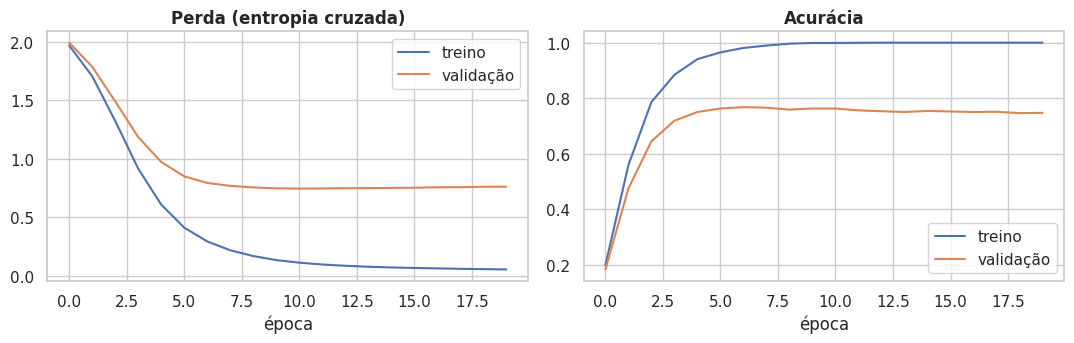

In [35]:
def es_split(ytr, seed=SEED):
    # fatia estratificada do treino reservada só para early stopping
    return train_test_split(np.arange(len(ytr)), test_size=CFG["ES_VAL_FRAC"], stratify=ytr, random_state=seed)

def train_manual(Xtr, ytr, Xva=None, yva=None, hidden=None, activation="relu", l2=0.0, epochs=None,
                 early_stop=True, **kw):
    net = MLPManual(Xtr.shape[1], hidden or CFG["HIDDEN"], K, activation, l2, CFG["LR"])
    es = {}
    if early_stop:
        a, b = es_split(ytr)
        es = dict(es_val=(Xtr[b], ytr[b]), patience=CFG["PATIENCE"])
        Xtr, ytr = Xtr[a], ytr[a]
    return net.fit(Xtr, ytr, Xva, yva, epochs=epochs or CFG["EPOCHS"], batch_size=CFG["BATCH"],
                   class_weight=CW, **es, **kw)

t0 = time.time()
net_ref = train_manual(Xtr_t, y[idx_tr], Xval_t, y[idx_val], activation="relu", l2=CFG["L2"], record=True)
m_manual = compute_metrics(y[idx_val], net_ref.predict_proba(Xval_t))
print(f"MLP manual (ReLU, L2) — {time.time()-t0:.1f}s | parou na época {net_ref.stopped_epoch} (melhor: {net_ref.best_epoch})")
print(pd.Series(m_manual).round(4).to_string())

h = net_ref.history
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(h["train_loss"], label="treino"); ax[0].plot(h["val_loss"], label="validação")
ax[0].set(title="Perda (entropia cruzada)", xlabel="época"); ax[0].legend()
ax[1].plot(h["train_acc"], label="treino"); ax[1].plot(h["val_acc"], label="validação")
ax[1].set(title="Acurácia", xlabel="época"); ax[1].legend()
fig.tight_layout(); fig.savefig(OUT/"figs"/"02_mlp_manual_curvas.png", dpi=150); plt.show()

## 3. Implementação equivalente em Keras/TensorFlow

Mesma arquitetura, mesmas inicializações (He/Glorot normal), mesma perda (entropia cruzada), mesmo otimizador (Adam, `lr`, `ε=1e-7`) e regularização L2 (`λ·ΣW²`, igual à da rede manual).
Se as duas implementações estiverem corretas, as curvas e métricas devem ser **muito próximas** (não idênticas: a ordem dos mini-lotes e as sementes de inicialização diferem).

Keras — 48.7s | parou na época 43


,MLP manual,Keras,|Δ|
accuracy,0.7559,0.7354,0.0205
precision_macro,0.7515,0.7278,0.0237
recall_macro,0.7511,0.7300,0.0211
f1_micro,0.7559,0.7354,0.0205
f1_macro,0.7508,0.7282,0.0226
auroc_macro,0.9564,0.9506,0.0058


Concordância das previsões manual × Keras: 86.6%


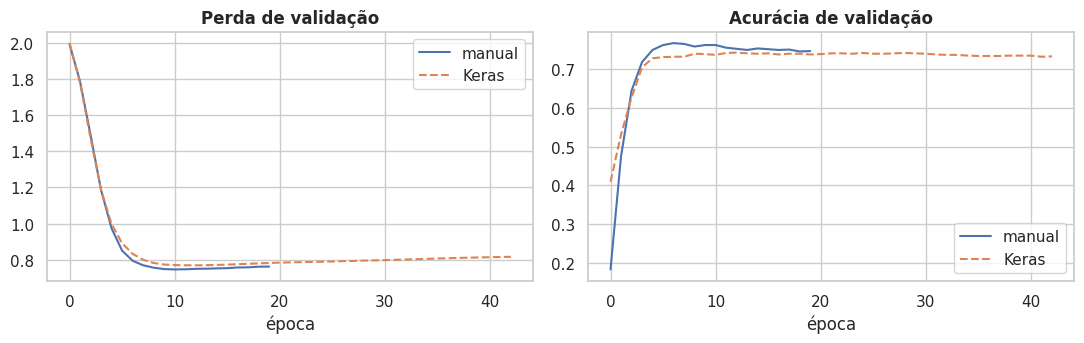

In [36]:
def build_keras(n_in, hidden, n_out, activation="relu", l2=0.0, lr=1e-3):
    init = "he_normal" if activation == "relu" else "glorot_normal"
    reg = keras.regularizers.l2(l2) if l2 > 0 else None
    layers = [keras.Input((n_in,))]
    layers += [keras.layers.Dense(h, activation=activation, kernel_initializer=init, kernel_regularizer=reg) for h in hidden]
    layers += [keras.layers.Dense(n_out, activation="softmax", kernel_initializer="glorot_normal", kernel_regularizer=reg)]
    model = keras.Sequential(layers)
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

class EvalLog(keras.callbacks.Callback):
    # registra perda (só entropia cruzada, sem o termo L2) e acurácia em um conjunto de avaliação a cada época
    def __init__(self, X, y_):
        super().__init__(); self.X, self.y = X, y_; self.loss, self.acc = [], []
    def on_epoch_end(self, epoch, logs=None):
        P = self.model.predict(self.X, verbose=0)
        self.loss.append(float(-np.log(P[np.arange(len(self.y)), self.y] + 1e-12).mean()))
        self.acc.append(float((P.argmax(1) == self.y).mean()))

def fit_predict(kind, Xtr, ytr, Xte, hidden=None, activation="relu", l2=0.0, epochs=None,
                yte=None, record=False, seed=SEED, early_stop=True):
    # treina 'manual' ou 'keras' (ambos com early stopping numa fatia interna do treino) e devolve (proba em Xte, histórico)
    hidden, epochs = hidden or CFG["HIDDEN"], epochs or CFG["EPOCHS"]
    Xfit, yfit, es_set = Xtr, ytr, None
    if early_stop:
        a, b = es_split(ytr, seed)
        Xfit, yfit, es_set = Xtr[a], ytr[a], (Xtr[b], ytr[b])
    if kind == "manual":
        net = MLPManual(Xtr.shape[1], hidden, K, activation, l2, CFG["LR"], seed)
        net.fit(Xfit, yfit, Xte if record else None, yte if record else None, epochs=epochs,
                batch_size=CFG["BATCH"], class_weight=CW, record=record, seed=seed,
                es_val=es_set, patience=CFG["PATIENCE"])
        net.history["stopped_epoch"] = net.stopped_epoch
        return net.predict_proba(Xte), net.history
    keras.utils.set_random_seed(seed)
    model = build_keras(Xtr.shape[1], hidden, K, activation, l2, CFG["LR"])
    cbs, ev = [], None
    if record and yte is not None:
        ev = EvalLog(to_dense(Xte, np.float32), yte); cbs.append(ev)
    val = None
    if es_set is not None:
        val = (to_dense(es_set[0], np.float32), es_set[1])
        cbs.append(keras.callbacks.EarlyStopping(monitor="val_loss", patience=CFG["PATIENCE"], min_delta=1e-4,
                                                 restore_best_weights=True))
    hist = model.fit(to_dense(Xfit, np.float32), yfit, epochs=epochs, batch_size=CFG["BATCH"], verbose=0,
                     validation_data=val, class_weight=CW, callbacks=cbs)
    proba = model.predict(to_dense(Xte, np.float32), verbose=0)
    keras.backend.clear_session()
    out = dict(stopped_epoch=len(hist.history["loss"]))
    if ev is not None:
        out.update(val_loss=ev.loss, val_acc=ev.acc)
    return proba, out

t0 = time.time()
P_keras, h_keras = fit_predict("keras", Xtr_t, y[idx_tr], Xval_t, activation="relu", l2=CFG["L2"],
                               yte=y[idx_val], record=True)
m_keras = compute_metrics(y[idx_val], P_keras)
P_manual = net_ref.predict_proba(Xval_t)
print(f"Keras — {time.time()-t0:.1f}s | parou na época {h_keras['stopped_epoch']}")
cmp = pd.DataFrame({"MLP manual": m_manual, "Keras": m_keras}).round(4)
cmp["|Δ|"] = (cmp["MLP manual"] - cmp["Keras"]).abs().round(4)
display(cmp)
print(f"Concordância das previsões manual × Keras: {(P_manual.argmax(1) == P_keras.argmax(1)).mean():.1%}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(h["val_loss"], label="manual"); ax[0].plot(h_keras["val_loss"], "--", label="Keras")
ax[0].set(title="Perda de validação", xlabel="época"); ax[0].legend()
ax[1].plot(h["val_acc"], label="manual"); ax[1].plot(h_keras["val_acc"], "--", label="Keras")
ax[1].set(title="Acurácia de validação", xlabel="época"); ax[1].legend()
fig.tight_layout(); fig.savefig(OUT/"figs"/"03_manual_vs_keras.png", dpi=150); plt.show()

## 4. Busca de hiperparâmetros com 5-fold cross-validation

Grade completa (12 configurações), sempre sobre o conjunto `tv` (o teste não é usado aqui):

* **Ativação:** ReLU × Sigmoide
* **Regularização:** sem × L2 ($\lambda = 10^{-4}$)
* **Neurônios por camada:** (32, 16), (64, 32), (128, 64)  (redes enxutas; ver `CFG["GRID_HIDDEN"]`)

Cada treino usa **early stopping** (paciência `CFG["PATIENCE"]`, restaurando os melhores pesos) numa fatia interna de 10% do treino da fold, então a fold de validação nunca influencia o treino.

Para cada configuração, reportamos a **média** das 5 folds e o **IC de 95%** ($\bar x \pm t_{0.975,4}\,s/\sqrt5$). O critério de escolha é o **macro-F1** (adequado ao desbalanceamento).
Os folds (e o TF-IDF de cada fold, ajustado só no treino do fold) são os mesmos para todas as configurações, o que permite comparações pareadas.

In [37]:
def prepare_folds(feat_fn, pool_idx, n_splits=5):
    """Pré-calcula (treino, validação, Xtr, Xva) de cada fold estratificado."""
    skf = StratifiedKFold(n_splits, shuffle=True, random_state=SEED)
    out = []
    for a, b in skf.split(pool_idx, y[pool_idx]):
        tr, va = pool_idx[a], pool_idx[b]
        Xtr, Xva = feat_fn(tr, va)
        out.append((tr, va, Xtr, Xva))
    return out

def cv_run(kind, folds, hidden, activation, l2, epochs=None):
    rows = []
    for tr, va, Xtr, Xva in folds:
        proba, _ = fit_predict(kind, Xtr, y[tr], Xva, hidden, activation, l2, epochs)
        rows.append(compute_metrics(y[va], proba))
    return pd.DataFrame(rows)

def summarize(df_cv, metrics=("accuracy", "f1_macro", "auroc_macro")):
    s = {}
    for m_ in metrics:
        mu, lo, hi = mean_ci(df_cv[m_])
        s[f"{m_}_mean"], s[f"{m_}_lo"], s[f"{m_}_hi"] = mu, lo, hi
    return s

t0 = time.time()
folds_tfidf = prepare_folds(lambda tr, va: tfidf_features(texts[tr], texts[va])[:2], idx_tv)
print(f"TF-IDF por fold pronto em {time.time()-t0:.1f}s")

GRID = dict(activation=["relu", "sigmoid"], l2=[0.0, CFG["L2"]], hidden=CFG["GRID_HIDDEN"])
cv_folds, rows = {}, []
for act, l2, hid in itertools.product(GRID["activation"], GRID["l2"], GRID["hidden"]):
    t1 = time.time()
    d = cv_run("manual", folds_tfidf, hid, act, l2)
    cv_folds[(act, l2, hid)] = d
    rows.append(dict(ativacao=act, regularizacao="L2" if l2 > 0 else "sem", neuronios=f"{hid[0]}-{hid[1]}",
                     _key=(act, l2, hid), **summarize(d)))
    print(f"  {act:8s} {'L2 ' if l2 else 'sem'} {hid}  F1-macro={rows[-1]['f1_macro_mean']:.3f}  ({time.time()-t1:.0f}s)")

res = pd.DataFrame(rows).sort_values("f1_macro_mean", ascending=False).reset_index(drop=True)
fmt = lambda r, m_: f"{r[m_+'_mean']:.3f} [{r[m_+'_lo']:.3f}, {r[m_+'_hi']:.3f}]"
table_cv = pd.DataFrame({"ativação": res.ativacao, "regularização": res.regularizacao, "neurônios": res.neuronios,
                         "acurácia (média [IC95%])": res.apply(lambda r: fmt(r, "accuracy"), axis=1),
                         "macro-F1 (média [IC95%])": res.apply(lambda r: fmt(r, "f1_macro"), axis=1),
                         "AUROC (média [IC95%])": res.apply(lambda r: fmt(r, "auroc_macro"), axis=1)})
table_cv.to_csv(OUT / "tabela_cv_grid.csv", index=False)
display(table_cv)
BEST_KEY = res.loc[0, "_key"]
BEST = dict(activation=BEST_KEY[0], l2=BEST_KEY[1], hidden=BEST_KEY[2])
print("\nMelhor configuração (macro-F1 médio):", BEST)

TF-IDF por fold pronto em 13.9s
  relu     sem (32, 16)  F1-macro=0.716  (25s)
  relu     sem (64, 32)  F1-macro=0.739  (26s)
  relu     sem (128, 64)  F1-macro=0.734  (45s)
  relu     L2  (32, 16)  F1-macro=0.714  (44s)
  relu     L2  (64, 32)  F1-macro=0.734  (29s)
  relu     L2  (128, 64)  F1-macro=0.736  (53s)
  sigmoid  sem (32, 16)  F1-macro=0.685  (61s)
  sigmoid  sem (64, 32)  F1-macro=0.724  (83s)
  sigmoid  sem (128, 64)  F1-macro=0.734  (123s)
  sigmoid  L2  (32, 16)  F1-macro=0.197  (94s)
  sigmoid  L2  (64, 32)  F1-macro=0.243  (148s)
  sigmoid  L2  (128, 64)  F1-macro=0.465  (324s)


,ativação,regularização,neurônios,acurácia (média [IC95%]),macro-F1 (média [IC95%]),AUROC (média [IC95%])
0,relu,sem,64-32,"0.748 [0.735, 0.761]","0.739 [0.724, 0.755]","0.954 [0.950, 0.958]"
1,relu,L2,128-64,"0.746 [0.729, 0.762]","0.736 [0.717, 0.755]","0.954 [0.951, 0.958]"
2,relu,L2,64-32,"0.744 [0.734, 0.753]","0.734 [0.722, 0.747]","0.953 [0.949, 0.956]"
3,sigmoid,sem,128-64,"0.744 [0.735, 0.753]","0.734 [0.723, 0.745]","0.955 [0.952, 0.957]"
4,relu,sem,128-64,"0.742 [0.733, 0.751]","0.734 [0.721, 0.747]","0.956 [0.953, 0.959]"
5,sigmoid,sem,64-32,"0.733 [0.718, 0.749]","0.724 [0.708, 0.740]","0.949 [0.945, 0.954]"
6,relu,sem,32-16,"0.725 [0.717, 0.734]","0.716 [0.706, 0.725]","0.943 [0.937, 0.948]"
7,relu,L2,32-16,"0.724 [0.708, 0.740]","0.714 [0.695, 0.732]","0.944 [0.937, 0.950]"
8,sigmoid,sem,32-16,"0.696 [0.686, 0.705]","0.685 [0.678, 0.693]","0.934 [0.930, 0.937]"
9,sigmoid,L2,128-64,"0.528 [0.513, 0.543]","0.465 [0.435, 0.495]","0.873 [0.867, 0.880]"



Melhor configuração (macro-F1 médio): {'activation': 'relu', 'l2': 0.0, 'hidden': (64, 32)}


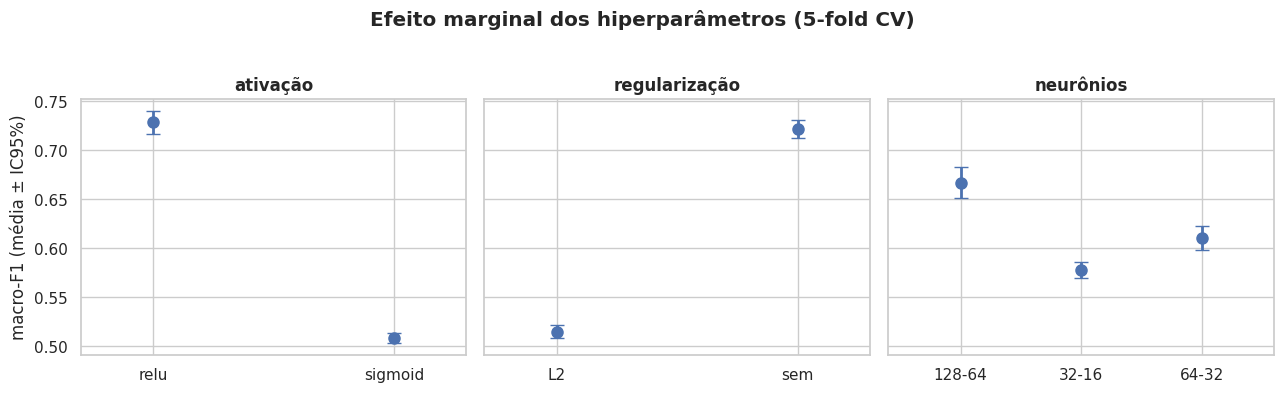

t pareado 1ª × 2ª melhor config: t=0.43, p=0.693  (indicativo; n=5 folds, folds não são independentes)


In [38]:
# ---- efeito de cada hiperparâmetro (média das 5 folds × demais configurações) com IC 95%
long = []
for (act, l2, hid), d in cv_folds.items():
    for f, v in enumerate(d["f1_macro"]):
        long.append(dict(fold=f, **{"ativação": act, "regularização": "L2" if l2 else "sem", "neurônios": f"{hid[0]}-{hid[1]}"}, f1_macro=v))
long = pd.DataFrame(long)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for a_, col in zip(ax, ["ativação", "regularização", "neurônios"]):
    # média por fold (sobre as demais configs) -> IC t sobre as 5 folds
    g = long.groupby([col, "fold"])["f1_macro"].mean().reset_index()
    stats_ = g.groupby(col)["f1_macro"].apply(lambda s: pd.Series(mean_ci(s), index=["m", "lo", "hi"])).unstack()
    a_.errorbar(range(len(stats_)), stats_["m"], yerr=[stats_["m"] - stats_["lo"], stats_["hi"] - stats_["m"]],
                fmt="o", capsize=5, lw=2, ms=8)
    a_.set_xticks(range(len(stats_))); a_.set_xticklabels(stats_.index); a_.set_title(col); a_.margins(x=0.3)
ax[0].set_ylabel("macro-F1 (média ± IC95%)")
fig.suptitle("Efeito marginal dos hiperparâmetros (5-fold CV)", y=1.03, fontweight="bold")
fig.tight_layout(); fig.savefig(OUT/"figs"/"04_efeito_hiperparametros.png", dpi=150, bbox_inches="tight"); plt.show()

# ---- teste t pareado (mesmas folds) entre a 1ª e a 2ª melhores configurações
k1, k2 = res.loc[0, "_key"], res.loc[1, "_key"]
diff = cv_folds[k1]["f1_macro"].to_numpy() - cv_folds[k2]["f1_macro"].to_numpy()
if np.allclose(diff, 0):
    print("1ª e 2ª melhores configurações tiveram resultados idênticos nas 5 folds (teste t não se aplica).")
else:
    t_, p_ = stats.ttest_rel(cv_folds[k1]["f1_macro"], cv_folds[k2]["f1_macro"])
    print(f"t pareado 1ª × 2ª melhor config: t={t_:.2f}, p={p_:.3f}  (indicativo; n=5 folds, folds não são independentes)")

In [39]:
# ---- validação cruzada da melhor configuração também no Keras (mesmos folds)
d_best_m = cv_folds[BEST_KEY]
d_best_k = cv_run("keras", folds_tfidf, BEST["hidden"], BEST["activation"], BEST["l2"])
rows = []
for nome, d in [("MLP manual", d_best_m), ("Keras", d_best_k)]:
    r = {"modelo": nome}
    for m_ in ["accuracy", "f1_macro", "auroc_macro"]:
        mu, lo, hi = mean_ci(d[m_]); r[m_] = f"{mu:.3f} [{lo:.3f}, {hi:.3f}]"
    rows.append(r)
cv_best_table = pd.DataFrame(rows); cv_best_table.to_csv(OUT / "tabela_cv_manual_vs_keras.csv", index=False)
display(cv_best_table)

,modelo,accuracy,f1_macro,auroc_macro
0,MLP manual,"0.748 [0.735, 0.761]","0.739 [0.724, 0.755]","0.954 [0.950, 0.958]"
1,Keras,"0.737 [0.728, 0.746]","0.728 [0.719, 0.736]","0.953 [0.949, 0.957]"


### 4.1 Sensibilidade ao tamanho do vocabulário TF-IDF

Controlar a esparsidade (`max_features`) é uma das alavancas contra o overfitting. Comparamos vários tamanhos com a melhor configuração, na partição treino/validação (`min_df` fixo em `CFG["MIN_DF"]`).

,max_features,atributos,f1_treino,f1_val,epocas,lacuna (treino-val)
0,200,200,0.657,0.592,21,0.065
1,500,500,0.774,0.666,18,0.108
2,1000,1000,0.829,0.686,16,0.143
3,2000,2000,0.915,0.705,16,0.210
4,4000,4000,0.968,0.759,16,0.209


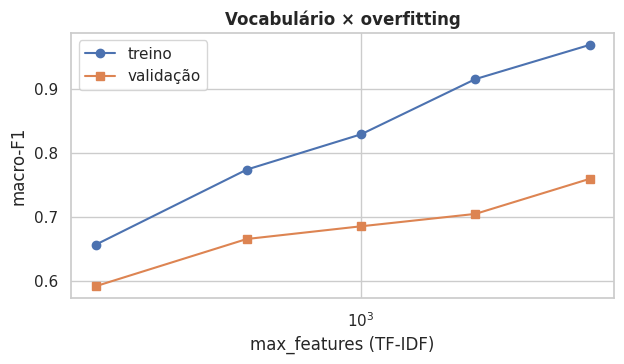

In [40]:
rows_f = []
for mf in ([100, 300, 600] if FAST else [200, 500, 1000, 2000, 4000]):
    Xa, Xb, _ = tfidf_features(texts[idx_tr], texts[idx_val], max_features=mf)
    net = train_manual(Xa, y[idx_tr], hidden=BEST["hidden"], activation=BEST["activation"], l2=BEST["l2"])
    rows_f.append(dict(max_features=mf, atributos=Xa.shape[1], f1_treino=f1_score(y[idx_tr], net.predict(Xa), average="macro"),
                       f1_val=f1_score(y[idx_val], net.predict(Xb), average="macro"), epocas=net.stopped_epoch))
mf_tab = pd.DataFrame(rows_f); mf_tab["lacuna (treino-val)"] = mf_tab.f1_treino - mf_tab.f1_val
display(mf_tab.round(3)); mf_tab.round(4).to_csv(OUT / "tabela_max_features.csv", index=False)
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.plot(mf_tab.max_features, mf_tab.f1_treino, "o-", label="treino"); ax.plot(mf_tab.max_features, mf_tab.f1_val, "s-", label="validação")
ax.set(xscale="log", xlabel="max_features (TF-IDF)", ylabel="macro-F1", title="Vocabulário × overfitting"); ax.legend()
fig.tight_layout(); fig.savefig(OUT/"figs"/"04b_max_features.png", dpi=150); plt.show()

## 5. Diagnósticos, métricas e análise de pesos
### 5.1 Curvas de aprendizado: overfitting, underfitting, viés e variância

Duas visões para a melhor configuração (como no livro, p. 127-131: treino × validação): (a) perda/acurácia **por época** — a linha tracejada marca a época restaurada pelo early stopping — e (b) macro-F1 em função do **tamanho do conjunto de treino**. Lacuna grande entre as curvas = variância alta (overfitting); as duas curvas altas de erro e próximas = viés alto (underfitting).
Heurística usada no diagnóstico automático (ajuste conforme o contexto do relatório):
*viés* ≈ $1-\text{F1}_\text{treino}$ (alto se > 0,20) e *variância* ≈ $\text{F1}_\text{treino}-\text{F1}_\text{val}$ (alta se > 0,10).

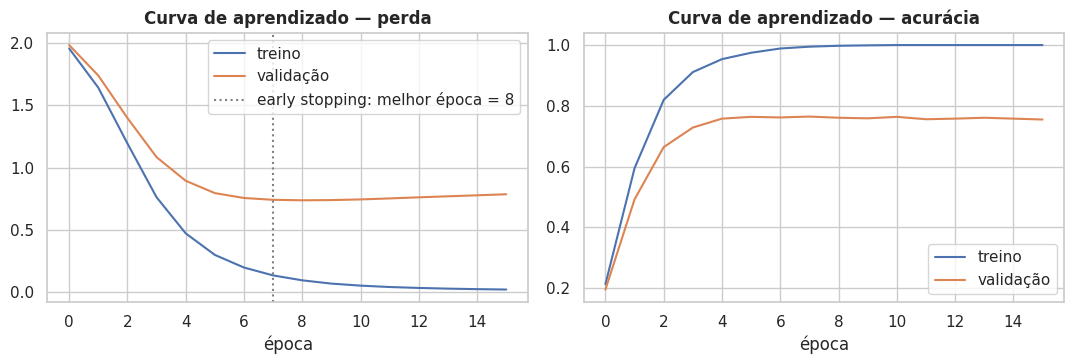

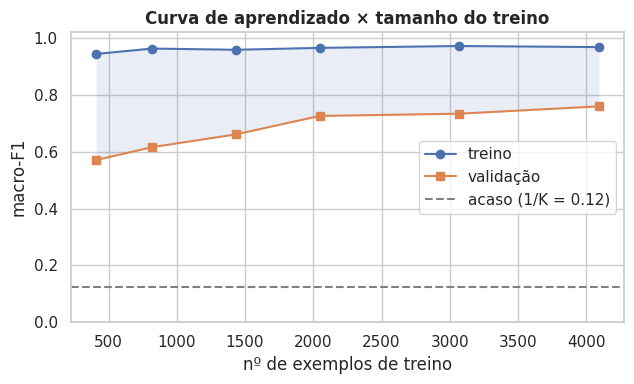

Viés (1 − F1 treino) = 0.032 | Variância (F1 treino − F1 val) = 0.209
Diagnóstico: ALTA VARIÂNCIA (overfitting) e viés baixo (o modelo ajusta bem o treino).
A curva de validação ainda sobe com mais dados -> mais dados ajudariam.


In [41]:
net_best = train_manual(Xtr_t, y[idx_tr], Xval_t, y[idx_val], hidden=BEST["hidden"], activation=BEST["activation"],
                        l2=BEST["l2"], record=True)
hb = net_best.history
best_ep = net_best.best_epoch - 1                 # época escolhida pelo early stopping

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(hb["train_loss"], label="treino"); ax[0].plot(hb["val_loss"], label="validação")
ax[0].axvline(best_ep, color="gray", ls=":", label=f"early stopping: melhor época = {best_ep+1}")
ax[0].set(title="Curva de aprendizado — perda", xlabel="época"); ax[0].legend()
ax[1].plot(hb["train_acc"], label="treino"); ax[1].plot(hb["val_acc"], label="validação")
ax[1].set(title="Curva de aprendizado — acurácia", xlabel="época"); ax[1].legend()
fig.tight_layout(); fig.savefig(OUT/"figs"/"05a_curvas_epocas.png", dpi=150); plt.show()

# ---- curva por tamanho do conjunto de treino
fracs = [0.1, 0.2, 0.35, 0.5, 0.75, 1.0]
ytr_ = y[idx_tr]; lc = []
for f in fracs:
    sub = np.arange(len(idx_tr)) if f == 1 else train_test_split(np.arange(len(idx_tr)), train_size=f, stratify=ytr_, random_state=SEED)[0]
    net = train_manual(Xtr_t[sub], ytr_[sub], hidden=BEST["hidden"], activation=BEST["activation"], l2=BEST["l2"])
    lc.append(dict(n=len(sub),
                   f1_treino=f1_score(ytr_[sub], net.predict(Xtr_t[sub]), average="macro"),
                   f1_val=f1_score(y[idx_val], net.predict(Xval_t), average="macro")))
lc = pd.DataFrame(lc)
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(lc.n, lc.f1_treino, "o-", label="treino"); ax.plot(lc.n, lc.f1_val, "s-", label="validação")
ax.axhline(1 / K, color="gray", ls="--", label=f"acaso (1/K = {1/K:.2f})")
ax.fill_between(lc.n, lc.f1_val, lc.f1_treino, alpha=0.12)
ax.set(title="Curva de aprendizado × tamanho do treino", xlabel="nº de exemplos de treino", ylabel="macro-F1", ylim=(0, 1.02)); ax.legend()
fig.tight_layout(); fig.savefig(OUT/"figs"/"05b_curva_tamanho_treino.png", dpi=150); plt.show()

f1_tr, f1_va = lc.f1_treino.iloc[-1], lc.f1_val.iloc[-1]
bias, var = 1 - f1_tr, f1_tr - f1_va
print(f"Viés (1 − F1 treino) = {bias:.3f} | Variância (F1 treino − F1 val) = {var:.3f}")
print("Diagnóstico:",
      ("ALTA VARIÂNCIA (overfitting) " if var > 0.10 else "variância moderada/baixa ") + "e " +
      ("ALTO VIÉS (underfitting)." if bias > 0.20 else "viés baixo (o modelo ajusta bem o treino)."))
print("Os dois lados da curva já convergiram?" if abs(lc.f1_val.iloc[-1] - lc.f1_val.iloc[-2]) < 0.01
      else "A curva de validação ainda sobe com mais dados -> mais dados ajudariam.")

### 5.2 Heatmaps da variação acumulada dos pesos e saturação (ReLU × Sigmoide)

Treinamos a mesma arquitetura com ReLU e com Sigmoide, **sem early stopping e com o mesmo número fixo de épocas** (`CFG["EPOCHS_TRACK"]`, para as colunas dos heatmaps serem comparáveis), registrando a cada época:

* a variação absoluta dos pesos que chegam a cada neurônio, $\sum_i |W_{ij}^{(\text{fim})}-W_{ij}^{(\text{início})}|$ — o heatmap mostra o **acúmulo** dessa variação ao longo das épocas (linhas = neurônios ordenados pelo total, colunas = épocas);
* a **saturação**: fração das ativações em regime saturado (sigmoide: $a<0{,}05$ ou $a>0{,}95$; ReLU: $a=0$) e fração de neurônios "mortos/travados" para toda a amostra monitorada;
* a **norma dos gradientes** por camada (indica *vanishing gradient*).

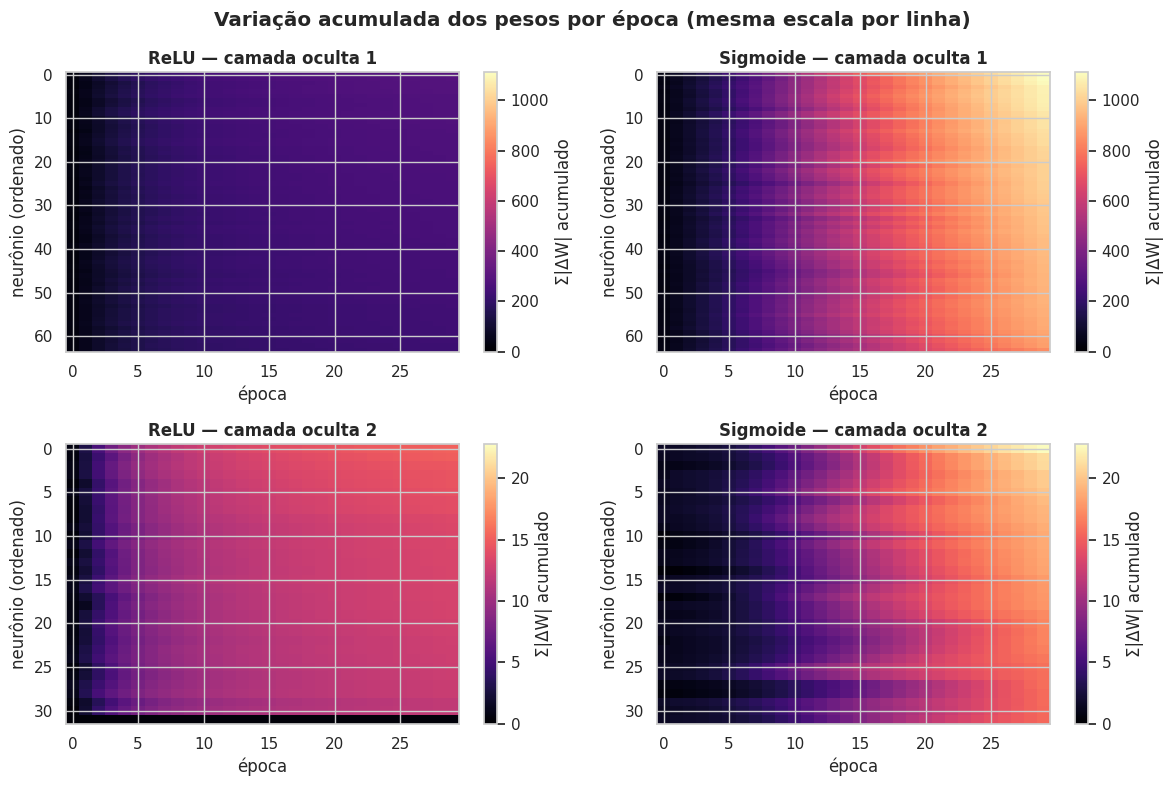

In [42]:
nets_w = {act: train_manual(Xtr_t, y[idx_tr], hidden=BEST["hidden"], activation=act, l2=BEST["l2"], track=True,
                            early_stop=False, epochs=CFG["EPOCHS_TRACK"])
          for act in ["relu", "sigmoid"]}
names = {"relu": "ReLU", "sigmoid": "Sigmoide"}

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for r in range(2):                                              # r = camada oculta 1 ou 2
    mats = {}
    for act, net in nets_w.items():
        M = np.cumsum(np.array([ep[r] for ep in net.history["dW"]]), axis=0).T    # (neurônios × épocas)
        mats[act] = M[np.argsort(-M[:, -1])]
    vmax = max(m.max() for m in mats.values())
    for c, act in enumerate(["relu", "sigmoid"]):
        im = axes[r, c].imshow(mats[act], aspect="auto", cmap="magma", vmin=0, vmax=vmax)
        axes[r, c].set(title=f"{names[act]} — camada oculta {r+1}", xlabel="época", ylabel="neurônio (ordenado)")
        fig.colorbar(im, ax=axes[r, c], label="Σ|ΔW| acumulado")
fig.suptitle("Variação acumulada dos pesos por época (mesma escala por linha)", fontweight="bold")
fig.tight_layout(); fig.savefig(OUT/"figs"/"05c_heatmaps_pesos.png", dpi=150); plt.show()

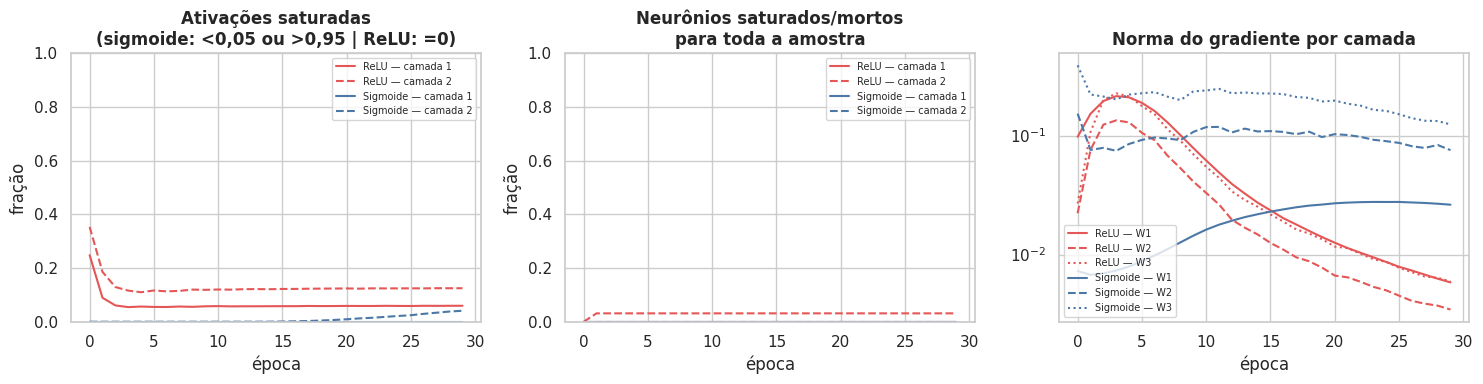

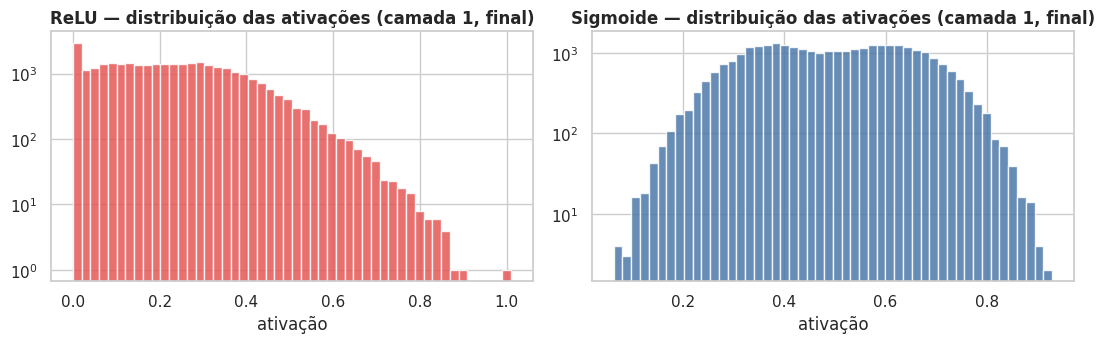

,ativação,saturação camada 1,saturação camada 2,neurônios travados c1,neurônios travados c2,‖∇W1‖ final,‖∇W3‖ final
0,ReLU,6.0%,12.5%,0.0%,3.1%,5.84e-03,5.94e-03
1,Sigmoide,0.0%,4.1%,0.0%,0.0%,2.62e-02,1.24e-01


In [43]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
col = {"relu": "#E45756", "sigmoid": "#4C78A8"}
for act, net in nets_w.items():
    hist_ = net.history
    sat, dead, gn = np.array(hist_["sat"]), np.array(hist_["dead"]), np.array(hist_["grad_norm"])
    for k, ls in zip(range(sat.shape[1]), ["-", "--"]):
        ax[0].plot(sat[:, k], ls=ls, color=col[act], label=f"{names[act]} — camada {k+1}")
        ax[1].plot(dead[:, k], ls=ls, color=col[act], label=f"{names[act]} — camada {k+1}")
    for k, ls in zip(range(gn.shape[1]), ["-", "--", ":"]):
        ax[2].plot(gn[:, k], ls=ls, color=col[act], label=f"{names[act]} — W{k+1}")
ax[0].set(title="Ativações saturadas\n(sigmoide: <0,05 ou >0,95 | ReLU: =0)", xlabel="época", ylabel="fração", ylim=(0, 1))
ax[1].set(title="Neurônios saturados/mortos\npara toda a amostra", xlabel="época", ylabel="fração", ylim=(0, 1))
ax[2].set(title="Norma do gradiente por camada", xlabel="época", yscale="log")
for a_ in ax: a_.legend(fontsize=7)
fig.tight_layout(); fig.savefig(OUT/"figs"/"05d_saturacao.png", dpi=150); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for a_, act in zip(ax, ["relu", "sigmoid"]):
    a_.hist(nets_w[act].monitor_acts[0].ravel(), bins=50, color=col[act], alpha=.85)
    a_.set(title=f"{names[act]} — distribuição das ativações (camada 1, final)", xlabel="ativação", yscale="log")
fig.tight_layout(); fig.savefig(OUT/"figs"/"05e_hist_ativacoes.png", dpi=150); plt.show()

summ = []
for act, net in nets_w.items():
    s_, d_ = net.history["sat"][-1], net.history["dead"][-1]
    summ.append({"ativação": names[act], "saturação camada 1": f"{s_[0]:.1%}", "saturação camada 2": f"{s_[1]:.1%}",
                 "neurônios travados c1": f"{d_[0]:.1%}", "neurônios travados c2": f"{d_[1]:.1%}",
                 "‖∇W1‖ final": f"{net.history['grad_norm'][-1][0]:.2e}", "‖∇W3‖ final": f"{net.history['grad_norm'][-1][-1]:.2e}"})
display(pd.DataFrame(summ))

### 5.3 Métricas no conjunto de teste: AUROC, precisão, revocação, micro-F1, macro-F1 × *Random Stratified Baseline*

Agora sim usamos o conjunto de teste: o TF-IDF é ajustado em `tv` (80%) e a melhor configuração é retreinada em `tv`.
O baseline *random stratified* sorteia a classe respeitando a distribuição do treino (média de 20 sementes); incluímos também o baseline da classe majoritária como referência.

In [44]:
Xtv, Xte, vec_tv = tfidf_features(texts[idx_tv], texts[idx_test])
ytv, yte = y[idx_tv], y[idx_test]

P_m, _ = fit_predict("manual", Xtv, ytv, Xte, BEST["hidden"], BEST["activation"], BEST["l2"])
P_k, _ = fit_predict("keras",  Xtv, ytv, Xte, BEST["hidden"], BEST["activation"], BEST["l2"])

def baseline_metrics(strategy, seeds=range(20)):
    ms = []
    for s in seeds:
        dm = DummyClassifier(strategy=strategy, random_state=s).fit(np.zeros((len(ytv), 1)), ytv)
        ms.append(compute_metrics(yte, dm.predict_proba(np.zeros((len(yte), 1)))))
    return pd.DataFrame(ms).mean().to_dict()

tbl = pd.DataFrame({"MLP manual (TF-IDF, 2 camadas)": compute_metrics(yte, P_m),
                    "Keras (TF-IDF, 2 camadas)":      compute_metrics(yte, P_k),
                    "Random Stratified (baseline)":   baseline_metrics("stratified"),
                    "Classe majoritária (referência)": baseline_metrics("prior", [0])}).T
tbl.columns = ["acurácia", "precisão (macro)", "revocação (macro)", "micro-F1", "macro-F1", "AUROC (macro OvR)"]
display(tbl.round(4))
EN_COLS = ["accuracy", "precision_macro", "recall_macro", "f1_micro", "f1_macro", "auroc_macro"]
for nome in tbl.index:
    TEST_RESULTS.append(dict(modelo=nome, **dict(zip(EN_COLS, tbl.loc[nome].values))))
tbl.round(4).to_csv(OUT / "tabela_teste_tfidf.csv")

print("\nRelatório por classe (MLP manual):")
rep = pd.DataFrame(classification_report(yte, P_m.argmax(1), target_names=classes, output_dict=True, zero_division=0)).T
display(rep.round(3))

,acurácia,precisão (macro),revocação (macro),micro-F1,macro-F1,AUROC (macro OvR)
"MLP manual (TF-IDF, 2 camadas)",0.7594,0.7585,0.7526,0.7594,0.7545,0.9610
"Keras (TF-IDF, 2 camadas)",0.7484,0.7457,0.7432,0.7484,0.7436,0.9587
Random Stratified (baseline),0.1254,0.1227,0.1226,0.1254,0.1225,0.4986
Classe majoritária (referência),0.1547,0.0193,0.1250,0.1547,0.0335,0.5000



Relatório por classe (MLP manual):


,precision,recall,f1-score,support
time travel,0.810,0.798,0.804,198.000
aliens,0.794,0.849,0.821,186.000
steampunk,0.689,0.713,0.701,174.000
robots,0.759,0.750,0.755,164.000
cyberpunk,0.753,0.748,0.751,163.000
military,0.883,0.840,0.861,144.000
alternate universe,0.613,0.674,0.642,129.000
alternate history,0.767,0.648,0.702,122.000
accuracy,0.759,0.759,0.759,0.759
macro avg,0.759,0.753,0.755,1280.000


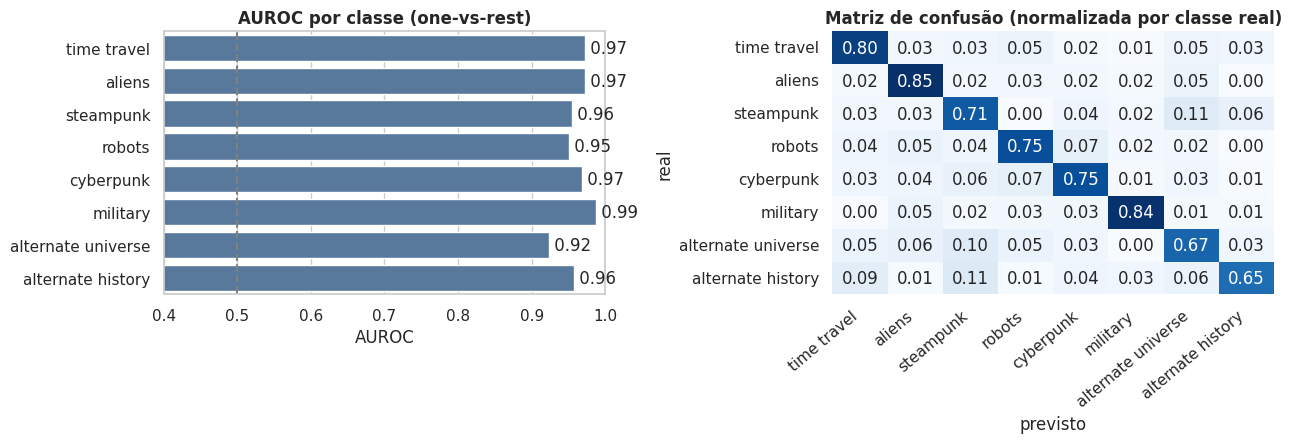

In [45]:
# ---- AUROC por classe e matriz de confusão
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
aucs = [roc_auc_score((yte == k).astype(int), P_m[:, k]) for k in range(K)]
sns.barplot(x=aucs, y=classes, ax=ax[0], color="#4C78A8")
ax[0].axvline(0.5, color="gray", ls="--"); ax[0].set(title="AUROC por classe (one-vs-rest)", xlim=(0.4, 1.0), xlabel="AUROC")
for i, v in enumerate(aucs):
    ax[0].text(v, i, f" {v:.2f}", va="center")
cm = confusion_matrix(yte, P_m.argmax(1), normalize="true")
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=classes, yticklabels=classes, ax=ax[1], cbar=False)
ax[1].set(title="Matriz de confusão (normalizada por classe real)", xlabel="previsto", ylabel="real")
plt.setp(ax[1].get_xticklabels(), rotation=40, ha="right")
fig.tight_layout(); fig.savefig(OUT/"figs"/"05f_auroc_confusao.png", dpi=150); plt.show()

### 5.4 Análise de erros e curvas precisão × revocação (cap. 3 do livro)

* **Análise de erros** (p. 100-104): matriz de confusão normalizada por linha com a **diagonal zerada**, para destacar *quais subgêneros são confundidos entre si*.
* **Curvas precisão × revocação** (p. 91-97): com classes raras, são mais informativas que a ROC; reportamos a *average precision* (AP) por classe e a prevalência (a AP de um classificador aleatório é a prevalência).

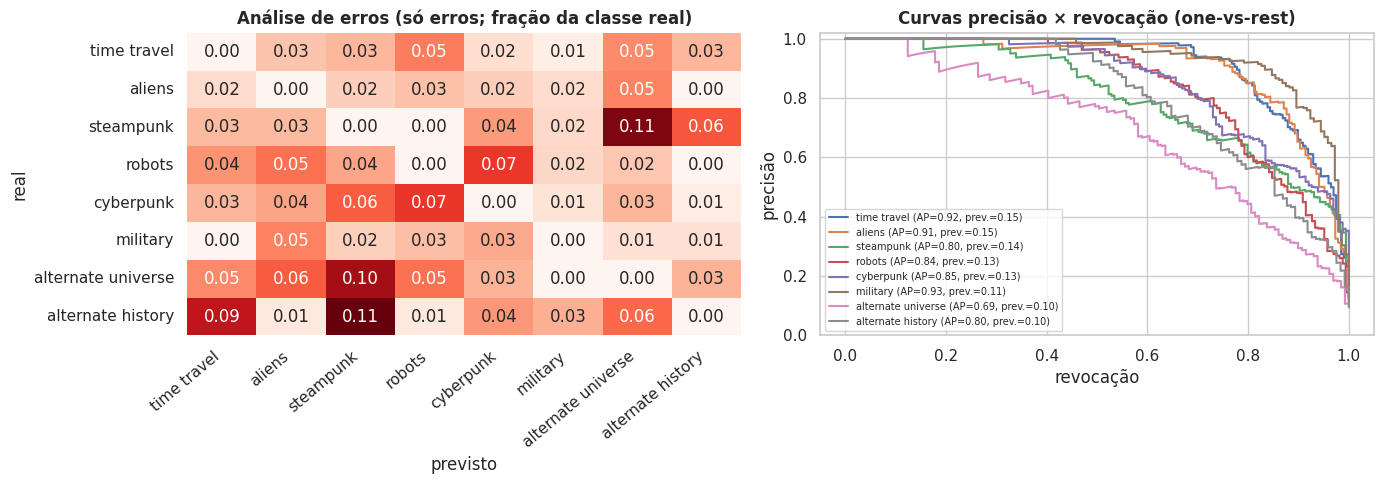

,classe,prevalencia,AP
0,time travel,0.155,0.915
1,aliens,0.145,0.906
2,steampunk,0.136,0.802
3,robots,0.128,0.839
4,cyberpunk,0.127,0.853
5,military,0.112,0.935
6,alternate universe,0.101,0.693
7,alternate history,0.095,0.804


Confusões mais frequentes (real -> previsto):
  alternate history      -> steampunk              11.5%
  steampunk              -> alternate universe     10.9%
  alternate universe     -> steampunk              10.1%
  alternate history      -> time travel            9.0%
  cyberpunk              -> robots                 7.4%


In [46]:
from sklearn.metrics import precision_recall_curve, average_precision_score
cm_err = confusion_matrix(yte, P_m.argmax(1), normalize="true"); np.fill_diagonal(cm_err, 0)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(cm_err, annot=True, fmt=".2f", cmap="Reds", xticklabels=classes, yticklabels=classes, ax=ax[0], cbar=False)
ax[0].set(title="Análise de erros (só erros; fração da classe real)", xlabel="previsto", ylabel="real")
plt.setp(ax[0].get_xticklabels(), rotation=40, ha="right")
ap_rows = []
for k in range(K):
    pr, rc, _ = precision_recall_curve((yte == k).astype(int), P_m[:, k])
    ap = average_precision_score((yte == k).astype(int), P_m[:, k]); prev = float(np.mean(yte == k))
    ax[1].plot(rc, pr, label=f"{classes[k]} (AP={ap:.2f}, prev.={prev:.2f})")
    ap_rows.append(dict(classe=classes[k], prevalencia=prev, AP=ap))
ax[1].set(title="Curvas precisão × revocação (one-vs-rest)", xlabel="revocação", ylabel="precisão", ylim=(0, 1.02)); ax[1].legend(fontsize=7)
fig.tight_layout(); fig.savefig(OUT/"figs"/"05g_erros_e_PR.png", dpi=150); plt.show()
display(pd.DataFrame(ap_rows).round(3))
top_conf = [(classes[i], classes[j], cm_err[i, j]) for i in range(K) for j in range(K) if i != j]
print("Confusões mais frequentes (real -> previsto):")
for a_, b_, v in sorted(top_conf, key=lambda t: -t[2])[:5]:
    print(f"  {a_:22s} -> {b_:22s} {v:.1%}")

## 6. Experimento com embeddings Skip-Gram

1. Treina-se um **Word2Vec Skip-Gram** (`sg=1`, janela 5, *negative sampling*) nas descrições do conjunto `tv` (o teste não participa; os rótulos também não são usados).
2. Cada descrição vira o **vetor concatenado** dos embeddings das suas primeiras `EMB_MAXLEN` palavras conhecidas (com *zero-padding*): entrada de dimensão `EMB_MAXLEN × EMB_DIM`, comparável à dimensão do TF-IDF.
3. A rede passa a ter **1 camada oculta** (dica da disciplina) e comparamos com o TF-IDF na mesma arquitetura (5-fold CV + teste).

Observação opcional: incluímos também a **média** dos embeddings (*mean-pooling*), que é invariante à posição das palavras, para contextualizar o resultado da concatenação (que depende da ordem).

Skip-Gram treinado em 199.5s | vocabulário: 21484 palavras | dim = 50
  world        -> strangeness, mechanism, croft, devolved, worldwar
  human        -> race, orpheus, experimentation, haan, emits
  series       -> trilogy, installment, morna, read, entry
  years        -> later, ago, months, passed, centuries
Features concatenadas: (6396, 2000) | média: (6396, 50)


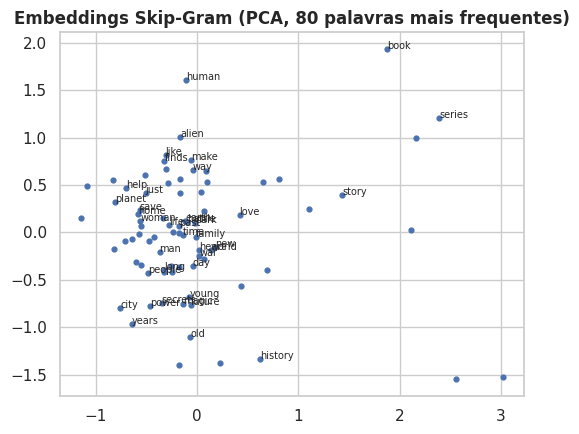

In [47]:
t0 = time.time()
w2v = Word2Vec(sentences=[tokens[i] for i in idx_tv], vector_size=CFG["EMB_DIM"], window=5, min_count=2, sg=1,
               negative=10, epochs=CFG["W2V_EPOCHS"], workers=1, seed=SEED)
wv = w2v.wv
print(f"Skip-Gram treinado em {time.time()-t0:.1f}s | vocabulário: {len(wv)} palavras | dim = {CFG['EMB_DIM']}")

# sanidade: vizinhos de algumas palavras frequentes
freq_words = [w for w in wv.index_to_key[:60] if len(w) > 4][:4]
for w in freq_words:
    print(f"  {w:12s} ->", ", ".join(x for x, _ in wv.most_similar(w, topn=5)))

D, ML = CFG["EMB_DIM"], CFG["EMB_MAXLEN"]
def unit(v): return v / (np.linalg.norm(v) + 1e-9)

def embed_concat(idx):
    X = np.zeros((len(idx), ML * D), dtype=np.float32)
    for r, i in enumerate(idx):
        k = 0
        for t in tokens[i]:
            if t in wv.key_to_index:
                X[r, k * D:(k + 1) * D] = unit(wv[t]); k += 1
                if k == ML: break
    return X

def embed_mean(idx):
    X = np.zeros((len(idx), D), dtype=np.float32)
    for r, i in enumerate(idx):
        vs = [unit(wv[t]) for t in tokens[i] if t in wv.key_to_index]
        if vs: X[r] = np.mean(vs, axis=0)
    return X

E_concat, E_mean = embed_concat(idx_all), embed_mean(idx_all)
print("Features concatenadas:", E_concat.shape, "| média:", E_mean.shape)

fig, ax = plt.subplots(figsize=(5.5, 4.5))                                  # projeção 2-D (PCA) das palavras mais frequentes
from sklearn.decomposition import PCA
top = wv.index_to_key[:80]; P2 = PCA(2, random_state=SEED).fit_transform(np.array([wv[w] for w in top]))
ax.scatter(P2[:, 0], P2[:, 1], s=12)
for w, (a_, b_) in list(zip(top, P2))[:40]:
    ax.annotate(w, (a_, b_), fontsize=7)
ax.set_title("Embeddings Skip-Gram (PCA, 80 palavras mais frequentes)")
fig.tight_layout(); fig.savefig(OUT/"figs"/"06a_embeddings_pca.png", dpi=150); plt.show()

In [48]:
H1 = (CFG["HIDDEN"][0],)                                   # 1 camada oculta
act, l2 = BEST["activation"], BEST["l2"]
print(f"Arquitetura com 1 camada oculta: {H1} | ativação={act} | L2={l2}")

folds_cat  = [(tr, va, E_concat[tr], E_concat[va]) for tr, va, _, _ in folds_tfidf]
folds_mean = [(tr, va, E_mean[tr],   E_mean[va])   for tr, va, _, _ in folds_tfidf]

cv_rows, cv_store = [], {}
for nome, folds in [("TF-IDF (1 camada)", folds_tfidf), ("Skip-Gram concatenado (1 camada)", folds_cat),
                    ("Skip-Gram média (1 camada) [extra]", folds_mean)]:
    t1 = time.time()
    d = cv_run("manual", folds, H1, act, l2); cv_store[nome] = d
    r = {"representação": nome}
    for m_ in ["accuracy", "f1_macro", "auroc_macro"]:
        mu, lo, hi = mean_ci(d[m_]); r[m_] = f"{mu:.3f} [{lo:.3f}, {hi:.3f}]"
    cv_rows.append(r); print(f"  {nome}: {time.time()-t1:.0f}s")
cv_emb = pd.DataFrame(cv_rows); cv_emb.to_csv(OUT / "tabela_cv_embeddings.csv", index=False)
display(cv_emb.rename(columns={"accuracy": "acurácia", "f1_macro": "macro-F1", "auroc_macro": "AUROC"}))

# referência: melhor MLP de 2 camadas com TF-IDF (CV)
mu, lo, hi = mean_ci(d_best_m["accuracy"]); print(f"Referência — TF-IDF, 2 camadas (melhor config): acurácia CV = {mu:.3f} [{lo:.3f}, {hi:.3f}]")
t_, p_ = stats.ttest_rel(cv_store["Skip-Gram concatenado (1 camada)"]["accuracy"], cv_store["TF-IDF (1 camada)"]["accuracy"])
print(f"t pareado acurácia Skip-Gram(concat) × TF-IDF: t={t_:.2f}, p={p_:.3f}")

Arquitetura com 1 camada oculta: (64,) | ativação=relu | L2=0.0
  TF-IDF (1 camada): 39s
  Skip-Gram concatenado (1 camada): 10s
  Skip-Gram média (1 camada) [extra]: 11s


,representação,acurácia,macro-F1,AUROC
0,TF-IDF (1 camada),"0.755 [0.746, 0.764]","0.746 [0.736, 0.756]","0.958 [0.954, 0.962]"
1,Skip-Gram concatenado (1 camada),"0.639 [0.636, 0.642]","0.624 [0.618, 0.629]","0.917 [0.911, 0.922]"
2,Skip-Gram média (1 camada) [extra],"0.715 [0.703, 0.727]","0.704 [0.695, 0.713]","0.943 [0.940, 0.946]"


Referência — TF-IDF, 2 camadas (melhor config): acurácia CV = 0.748 [0.735, 0.761]
t pareado acurácia Skip-Gram(concat) × TF-IDF: t=-36.63, p=0.000


,representação,implementação,accuracy,precision_macro,recall_macro,f1_micro,f1_macro,auroc_macro
0,TF-IDF (1 camada),MLP manual,0.7562,0.7547,0.7497,0.7562,0.7514,0.9633
1,TF-IDF (1 camada),Keras,0.7594,0.7586,0.7524,0.7594,0.7546,0.9628
2,Skip-Gram concatenado (1 camada),MLP manual,0.6359,0.6476,0.6240,0.6359,0.6261,0.9145
3,Skip-Gram concatenado (1 camada),Keras,0.6438,0.6565,0.6351,0.6438,0.6400,0.9148
4,Skip-Gram média (1 camada) [extra],MLP manual,0.7070,0.7087,0.6975,0.7070,0.7005,0.9411
5,Skip-Gram média (1 camada) [extra],Keras,0.7031,0.7026,0.6931,0.7031,0.6954,0.9408


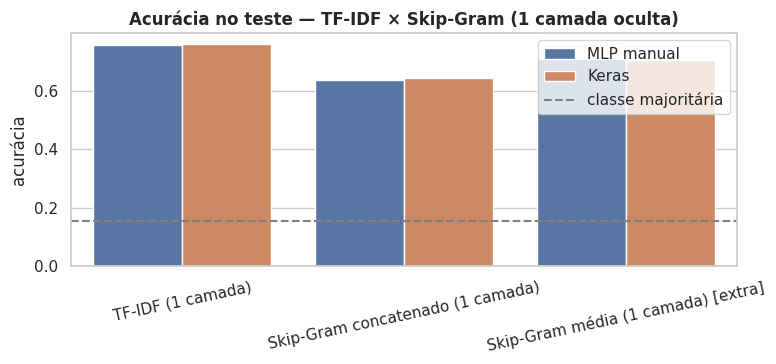

In [49]:
# ---- avaliação no conjunto de teste (manual e Keras)
rows_emb = []
reps = {"TF-IDF (1 camada)": (Xtv, Xte),
        "Skip-Gram concatenado (1 camada)": (E_concat[idx_tv], E_concat[idx_test]),
        "Skip-Gram média (1 camada) [extra]": (E_mean[idx_tv], E_mean[idx_test])}
for nome, (A_, B_) in reps.items():
    for kind, kn in [("manual", "MLP manual"), ("keras", "Keras")]:
        P_, _ = fit_predict(kind, A_, ytv, B_, H1, act, l2)
        met = compute_metrics(yte, P_)
        rows_emb.append({"representação": nome, "implementação": kn, **met})
        TEST_RESULTS.append(dict(modelo=f"{kn} — {nome}", accuracy=met["accuracy"], precision_macro=met["precision_macro"],
                                 recall_macro=met["recall_macro"], f1_micro=met["f1_micro"], f1_macro=met["f1_macro"],
                                 auroc_macro=met["auroc_macro"]))
emb_test = pd.DataFrame(rows_emb)
emb_test.round(4).to_csv(OUT / "tabela_teste_embeddings.csv", index=False)
display(emb_test.round(4))

fig, ax = plt.subplots(figsize=(8, 3.8))
sns.barplot(data=emb_test, x="representação", y="accuracy", hue="implementação", ax=ax)
ax.axhline(tbl.loc["Classe majoritária (referência)", "acurácia"], color="gray", ls="--", label="classe majoritária")
ax.set(title="Acurácia no teste — TF-IDF × Skip-Gram (1 camada oculta)", xlabel="", ylabel="acurácia"); ax.legend()
plt.setp(ax.get_xticklabels(), rotation=12); fig.tight_layout()
fig.savefig(OUT/"figs"/"06b_embeddings_vs_tfidf.png", dpi=150); plt.show()

## 7. Resumo dos resultados e conclusão

,acurácia,precisão (macro),revocação (macro),micro-F1,macro-F1,AUROC (macro)
modelo,,,,,,
Keras — TF-IDF (1 camada),0.7594,0.7586,0.7524,0.7594,0.7546,0.9628
"MLP manual (TF-IDF, 2 camadas)",0.7594,0.7585,0.7526,0.7594,0.7545,0.9610
MLP manual — TF-IDF (1 camada),0.7562,0.7547,0.7497,0.7562,0.7514,0.9633
"Keras (TF-IDF, 2 camadas)",0.7484,0.7457,0.7432,0.7484,0.7436,0.9587
MLP manual — Skip-Gram média (1 camada) [extra],0.7070,0.7087,0.6975,0.7070,0.7005,0.9411
Keras — Skip-Gram média (1 camada) [extra],0.7031,0.7026,0.6931,0.7031,0.6954,0.9408
Keras — Skip-Gram concatenado (1 camada),0.6438,0.6565,0.6351,0.6438,0.6400,0.9148
MLP manual — Skip-Gram concatenado (1 camada),0.6359,0.6476,0.6240,0.6359,0.6261,0.9145
Random Stratified (baseline),0.1254,0.1227,0.1226,0.1254,0.1225,0.4986


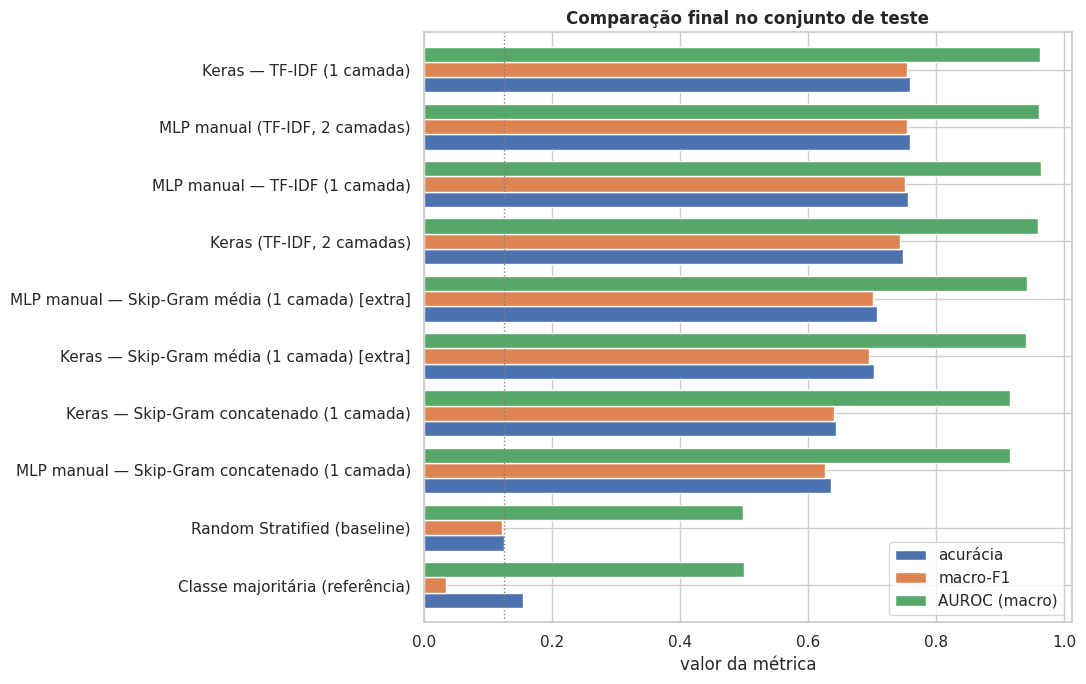


RESUMO AUTOMÁTICO (use como ponto de partida para o texto do relatório)
- Problema: 8 subgêneros (time travel, aliens, steampunk, robots, cyberpunk, military, alternate universe, alternate history); razão de desbalanceamento 1.6x; 6396 livros.
- Melhor configuração (5-fold, macro-F1): ativação=relu, L2=não, neurônios=(64, 32).
- Teste: macro-F1 = 0.755 (baseline estratificado = 0.122); AUROC = 0.961 (baseline = 0.499).
- Rede manual × Keras: diferença de macro-F1 de 0.011 -> implementações consistentes.
- Skip-Gram (concat., 1 camada) acurácia = 0.636 vs TF-IDF (1 camada) = 0.756.



In [50]:
final = pd.DataFrame(TEST_RESULTS).drop_duplicates("modelo", keep="last").set_index("modelo")
final.columns = ["acurácia", "precisão (macro)", "revocação (macro)", "micro-F1", "macro-F1", "AUROC (macro)"]
final = final.sort_values("macro-F1", ascending=False)
final.round(4).to_csv(OUT / "resumo_final_teste.csv")
display(final.round(4))

fig, ax = plt.subplots(figsize=(11, 0.55 * len(final) + 1.5))
final[["acurácia", "macro-F1", "AUROC (macro)"]].iloc[::-1].plot.barh(ax=ax, width=0.8)
ax.axvline(1 / K, color="gray", ls=":", lw=1)
ax.set(title="Comparação final no conjunto de teste", xlabel="valor da métrica", ylabel=""); ax.legend(loc="lower right")
fig.tight_layout(); fig.savefig(OUT/"figs"/"07_resumo_final.png", dpi=150); plt.show()

# ---- resumo textual com os números reais desta execução
b = final.loc[[i for i in final.index if "TF-IDF, 2 camadas" in i and "manual" in i.lower()][0]]
base = final.loc["Random Stratified (baseline)"]
is_man = emb_test["implementação"] == "MLP manual"
emb_c = emb_test[is_man & emb_test["representação"].str.contains("concatenado")].iloc[0]
tf1 = emb_test[is_man & (emb_test["representação"] == "TF-IDF (1 camada)")].iloc[0]
print(f"""
RESUMO AUTOMÁTICO (use como ponto de partida para o texto do relatório)
- Problema: {K} subgêneros ({', '.join(classes)}); razão de desbalanceamento {dist.max()/dist.min():.1f}x; {len(df)} livros.
- Melhor configuração (5-fold, macro-F1): ativação={BEST['activation']}, L2={'sim' if BEST['l2']>0 else 'não'}, neurônios={BEST['hidden']}.
- Teste: macro-F1 = {b['macro-F1']:.3f} (baseline estratificado = {base['macro-F1']:.3f}); AUROC = {b['AUROC (macro)']:.3f} (baseline = {base['AUROC (macro)']:.3f}).
- Rede manual × Keras: diferença de macro-F1 de {abs(tbl.iloc[0]['macro-F1']-tbl.iloc[1]['macro-F1']):.3f} -> implementações consistentes.
- Skip-Gram (concat., 1 camada) acurácia = {emb_c['accuracy']:.3f} vs TF-IDF (1 camada) = {tf1['accuracy']:.3f}.
""")

### Roteiro sugerido para a conclusão do relatório / apresentação (15 min)

1. **Problema e dados (2 min):** dataset, subgêneros escolhidos, desbalanceamento (gráfico 01), limpeza e TF-IDF.
2. **Implementação (3 min):** MLP manual (equações do forward/backprop, *gradient check*) e validação contra o Keras (figura 03).
3. **Hiperparâmetros (3 min):** tabela do 5-fold com IC 95% e efeito marginal de ativação, L2 e nº de neurônios (figuras 04).
4. **Diagnósticos (3 min):** curvas de aprendizado → viés × variância (05a/05b); heatmaps e saturação ReLU × Sigmoide (05c–05e).
5. **Métricas e embeddings (3 min):** AUROC/P/R/F1 × baseline (05f, tabela) e Skip-Gram × TF-IDF com 1 camada (06b).
6. **Conclusões (1 min):** o que funcionou, limitações (rótulos ruidosos/sobrepostos, descrições curtas, ordem das palavras na concatenação) e próximos passos (class weights, early stopping, CNN/LSTM, embeddings pré-treinados).

**Limitações a mencionar:** (i) o rótulo é o **arquivo** de origem (a lista de um livro no Goodreads), então subgêneros se sobrepõem e há ruído de rótulo; (ii) livros em 2+ arquivos foram descartados (`MULTI_POLICY`), o que muda levemente o desbalanceamento; (iii) a descrição pode conter o próprio nome do subgênero ("cyberpunk"), o que facilita a tarefa; (iv) a coluna `Genres` não foi usada como atributo porque **vazaria o rótulo**.

**Pontos para discutir no texto:** (i) por que o macro-F1 é menor que a acurácia em dados desbalanceados; (ii) se os ICs das configurações se sobrepõem (então a escolha não é estatisticamente forte); (iii) por que a sigmoide satura/atenua gradientes e a ReLU pode ter neurônios mortos; (iv) por que a concatenação de embeddings tende a perder para o TF-IDF (dependência de posição e truncamento) — e o que a média dos embeddings mostra.

### Referências do livro usadas neste trabalho
*Mãos à Obra: Aprendizado de Máquina com Scikit-Learn, Keras & TensorFlow* — parada antecipada (p. 139, 313), regularização ℓ2 sobre pesos e não sobre bias (p. 313-315), inicialização He (p. 285), curvas de aprendizado e viés/variância (p. 127-131), validação cruzada e amostragem estratificada (cap. 2-3), precisão/revocação, ROC/AUC e F1 (p. 90-97), classificação multiclasse e análise de erros (p. 97-104).